In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
import os
from collections import Counter
import random
import warnings
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts, OneCycleLR

# Torchvision imports
import torchvision.transforms as T
from torchvision.transforms import functional as TF

# timm for EfficientNetV2
import timm

# Sklearn for cross-validation
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Progress bar
from tqdm.notebook import tqdm

# Set seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Paths (data is in parent directory)
BASE_PATH = Path("../bdma-07-competition-2026/BDMA7_project_files")
TRAIN_PATH = BASE_PATH / "train_images"
VAL_PATH = BASE_PATH / "val_images"
TEST_PATH = BASE_PATH / "test_images"

Using device: mps


In [2]:
# ============================================
# Load Metadata & Class Mapping
# ============================================

# Load metadata
train_df = pd.read_csv(BASE_PATH / "train_metadata.csv")
val_df = pd.read_csv(BASE_PATH / "val_metadata.csv")
sample_submission = pd.read_csv(BASE_PATH / "sample_submission.csv")

print(f"Train samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples: {len(sample_submission)}")

# Class mapping 
class_mapping = {'Groove_billed_Ani': 0, 'Red_winged_Blackbird': 1, 'Rusty_Blackbird': 2, 'Gray_Catbird': 3, 
                 'Brandt_Cormorant': 4, 'Eastern_Towhee': 5, 'Indigo_Bunting': 6, 'Brewer_Blackbird': 7, 
                 'Painted_Bunting': 8, 'Bobolink': 9, 'Lazuli_Bunting': 10, 'Yellow_headed_Blackbird': 11, 
                 'American_Crow': 12, 'Fish_Crow': 13, 'Brown_Creeper': 14, 'Yellow_billed_Cuckoo': 15, 
                 'Yellow_breasted_Chat': 16, 'Black_billed_Cuckoo': 17, 'Gray_crowned_Rosy_Finch': 18, 'Bronzed_Cowbird': 19}

print(f"Number of classes: {len(class_mapping)}")

Train samples: 1082
Validation samples: 103
Test samples: 400
Number of classes: 20


## Note: Freeze Backbone Always Option

The `freeze_backbone_always` option has been added to the config. When set to `True`:
- The backbone will remain frozen throughout the entire training process
- Only the classifier head will be trained
- Stage 2 (unfreezing) will be skipped
- Training will run for `freeze_backbone_epochs + unfreeze_epochs` epochs, all with frozen backbone

**To use this option:**
1. Set `freeze_backbone_always = True` in the Config class
2. The training function will automatically handle this (code updates needed in training function)

**Benefits:**
- Faster training (only ~353k parameters vs 20M)
- Lower memory usage
- Preserves all pretrained features
- Good for when you have limited data or want to use the model as a feature extractor

In [3]:
# ============================================
# Configuration (imported from config.py)
# ============================================
# Edit config.py to change experiment settings

from config import Config
# Optional: Import presets for quick configuration
# from config import preset_quick_test, preset_frozen_backbone, preset_two_stage_progressive

# Reload config module if you've made changes to config.py
import importlib
import config as config_module
importlib.reload(config_module)
from config import Config

config = Config()

# ============================================
# Optional: Apply a preset
# ============================================
# Uncomment one of these to quickly apply predefined settings:
# from config import preset_quick_test, preset_frozen_backbone, preset_two_stage_progressive
# config = preset_quick_test(config)       # For quick testing/debugging
# config = preset_frozen_backbone(config)  # Train only classifier head
# config = preset_two_stage_progressive(config)  # Two-stage with progressive unfreezing

# ============================================
# Optional: Override specific settings here
# ============================================
# config.batch_size = 32
# config.n_folds = 3
# config.freeze_backbone_epochs = 10
print(f"Model: {config.model_name}")
print(f"Image size: {config.img_size}x{config.img_size}")
print(f"Batch size: {config.batch_size}")
print(f"K-Folds: {config.n_folds}")
print(f"\nTransfer Learning Strategy:")
print(f"  - Enabled: {config.use_transfer_learning}")
if config.use_transfer_learning:
    print(f"  - Freeze backbone always: {config.freeze_backbone_always}")
    if config.freeze_backbone_always:
        print(f"    → Backbone will remain frozen throughout training (classifier only)")
    else:
        print(f"  - Freeze backbone epochs: {config.freeze_backbone_epochs}")
        print(f"  - Unfreeze epochs: {config.unfreeze_epochs}")
        print(f"  - Unfreeze strategy: {'All layers' if config.unfreeze_all_layers else f'Last {config.unfreeze_last_n_blocks} blocks (progressive)'}")
    print(f"  - Total epochs: {config.total_epochs}")
    print(f"  - Head LR: {config.learning_rate_head}")
    print(f"  - Backbone LR: {config.learning_rate_backbone}")

print(f"\nClassifier Head:")
head_type = getattr(config, 'head_type', 'default')
if head_type == 'default':
    print(f"  - Type: default (Linear 1280 → {config.num_classes})")
elif head_type == 'mlp':
    print(f"  - Type: mlp (Linear → BN → ReLU → Dropout → Linear)")
    print(f"  - Hidden dim: {getattr(config, 'head_hidden_dim', 512)}")
    print(f"  - Dropout: {getattr(config, 'head_dropout', 0.3)}")
elif head_type == 'mlp_deep':
    print(f"  - Type: mlp_deep (2 hidden layers)")
    print(f"  - Hidden dims: {getattr(config, 'head_hidden_dim', 512)} → {getattr(config, 'head_hidden_dim_2', 256)}")
    print(f"  - Dropout: {getattr(config, 'head_dropout', 0.3)}")

print(f"\nVoting Methods:")
print(f"  - TTA voting: {config.tta_voting}")
print(f"  - Ensemble voting: {config.ensemble_voting}")

print(f"\nCheckpoint Settings:")
print(f"  - Checkpoint strategy: {config.checkpoint_strategy}")
print(f"  - Save all epochs: {config.save_all_epochs}")
print(f"  - Selected folds: {config.selected_folds if config.selected_folds else 'All folds'}")

Model: convnext_tiny.fb_in22k_ft_in1k_384
Image size: 384x384
Batch size: 16
K-Folds: 5

Transfer Learning Strategy:
  - Enabled: True
  - Freeze backbone always: False
  - Freeze backbone epochs: 10
  - Unfreeze epochs: 20
  - Unfreeze strategy: Last 2 blocks (progressive)
  - Total epochs: 30
  - Head LR: 0.001
  - Backbone LR: 1e-05

Classifier Head:
  - Type: mlp (Linear → BN → ReLU → Dropout → Linear)
  - Hidden dim: 512
  - Dropout: 0.3

Voting Methods:
  - TTA voting: mean
  - Ensemble voting: mean

Checkpoint Settings:
  - Checkpoint strategy: best
  - Save all epochs: True
  - Selected folds: All folds


In [4]:
# ============================================
# Data Augmentation Transforms
# ============================================

# ImageNet normalization values
# per-channel mean and standard deviation computed from the ImageNet training set (1.2M images).
# Pretrained models expect this normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def get_train_transforms(config):
    """
    Training augmentations:
    - Random resized crop
    - Horizontal flip
    - Color jitter (brightness, contrast, saturation, hue)
    - Random rotation (±15°)
    - Random erasing (Cutout)
    """
    return T.Compose([
        # Random crops and resizes
        T.RandomResizedCrop(
            config.img_size, 
            scale=(0.8, 1.0),
            ratio=(0.9, 1.1)
        ),
        # Horizontal flip
        T.RandomHorizontalFlip(p=0.5),
        # Random rotation ±15°
        T.RandomRotation(degrees=config.rotation_degrees),
        # Color jitter
        T.ColorJitter(
            brightness=config.color_jitter['brightness'],
            contrast=config.color_jitter['contrast'],
            saturation=config.color_jitter['saturation'],
            hue=config.color_jitter['hue']
        ),
        # Convert to tensor
        T.ToTensor(),
        # Normalize
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        # Random erasing (Cutout)
        T.RandomErasing(
            p=config.random_erasing_prob,
            scale=(0.02, 0.2), # The erased area is 2% to 20% of the total image area
            ratio=(0.3, 3.3) # Width/height ratio of the erased rectangle
        )
    ])

def get_val_transforms(config):
    """
    Validation transforms - minimal processing
    Used in the validation set
    """
    return T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

def get_tta_transforms(config):
    """
    Test Time Augmentation transforms - multiple variants
    Returns a list of transform pipelines
    Used in the test set
    """
    tta_list = []
    
    # Original (center crop)
    tta_list.append(T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    # Horizontal flip
    tta_list.append(T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.RandomHorizontalFlip(p=1.0),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    # Slight rotation +10
    tta_list.append(T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.RandomRotation(degrees=(10, 10)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    # Slight rotation -10
    tta_list.append(T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.RandomRotation(degrees=(-10, -10)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    # Center crop with larger resize
    tta_list.append(T.Compose([
        T.Resize(int(config.img_size * 1.1)),
        T.CenterCrop(config.img_size),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    return tta_list

print("Transforms defined successfully!")
print(f"Training augmentations: Random crops, H-flip, Rotation ±{config.rotation_degrees}°, Color jitter, Random erasing")
print(f"TTA variants: {len(get_tta_transforms(config))}")

Transforms defined successfully!
Training augmentations: Random crops, H-flip, Rotation ±15°, Color jitter, Random erasing
TTA variants: 5


In [5]:
# ============================================
# Dataset Classes
# ============================================

class BirdsDataset(Dataset):
    """Dataset for bird classification with augmentation support"""
    
    def __init__(self, df, base_path, transform=None):
        self.df = df.reset_index(drop=True)
        self.base_path = Path(base_path)
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.base_path / row['path']
        label = row['class_idx']
        
        # Load image
        image = Image.open(img_path).convert('RGB')
        
        # Apply transforms
        if self.transform:
            image = self.transform(image)
            
        return image, label


class BirdsTestDataset(Dataset):
    """Dataset for test images (no labels)"""
    
    def __init__(self, image_dir, transform=None):
        self.image_dir = Path(image_dir)
        self.image_files = sorted(list(self.image_dir.glob('*/*.jpg')))
        self.transform = transform
        
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        img_path = self.image_files[idx]
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        return image, img_path.name


class TTADataset(Dataset):
    """Dataset wrapper for TTA - returns multiple augmented versions"""
    
    def __init__(self, image_paths, tta_transforms):
        self.image_paths = image_paths
        self.tta_transforms = tta_transforms
        
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        
        # Apply all TTA transforms
        augmented_images = []
        for transform in self.tta_transforms:
            augmented_images.append(transform(image))
            
        return torch.stack(augmented_images), Path(img_path).name

print("Dataset classes defined!")

Dataset classes defined!


In [6]:
# ============================================
# Model Definition
# ============================================

def build_classifier_head(in_features, config):
    """
    Build a custom classifier head based on config settings.
    
    Args:
        in_features: Number of input features from backbone (e.g., 1280 for EfficientNetV2-S)
        config: Configuration object with head settings
    
    Returns:
        nn.Module: The classifier head
    """
    head_type = getattr(config, 'head_type', 'default')
    num_classes = config.num_classes
    hidden_dim = getattr(config, 'head_hidden_dim', 512)
    hidden_dim_2 = getattr(config, 'head_hidden_dim_2', 256)
    dropout = getattr(config, 'head_dropout', 0.3)
    use_bn = getattr(config, 'head_use_batchnorm', True)
    
    if head_type == 'default':
        # Single linear layer (timm default behavior)
        return nn.Linear(in_features, num_classes)
    
    elif head_type == 'mlp':
        # MLP with one hidden layer: Linear → BN → ReLU → Dropout → Linear
        layers = [nn.Linear(in_features, hidden_dim)]
        if use_bn:
            layers.append(nn.BatchNorm1d(hidden_dim))
        layers.extend([
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, num_classes)
        ])
        return nn.Sequential(*layers)
    
    elif head_type == 'mlp_deep':
        # Deeper MLP with two hidden layers
        layers = [nn.Linear(in_features, hidden_dim)]
        if use_bn:
            layers.append(nn.BatchNorm1d(hidden_dim))
        layers.extend([
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, hidden_dim_2)
        ])
        if use_bn:
            layers.append(nn.BatchNorm1d(hidden_dim_2))
        layers.extend([
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim_2, num_classes)
        ])
        return nn.Sequential(*layers)
    
    else:
        raise ValueError(f"Unknown head_type: {head_type}. Use 'default', 'mlp', or 'mlp_deep'")


def create_model(config, pretrained=True, freeze_backbone=False):
    """
    Create model with pretrained weights and custom classification head.
    Supports EfficientNetV2, ConvNeXt, and other timm models.
    
    Args:
        config: Configuration object
        pretrained: Whether to use pretrained weights
        freeze_backbone: If True, freeze all backbone layers (only train classifier head)
    """
    head_type = getattr(config, 'head_type', 'default')
    
    # Build and attach custom classifier head
    if head_type == 'default':
        # Use default timm head
        model = timm.create_model(
            config.model_name,
            pretrained=pretrained,
            num_classes=config.num_classes,
            drop_rate=0.3
        )
    else:
        # Create model with num_classes=0 to get features only
        model = timm.create_model(
            config.model_name,
            pretrained=pretrained,
            num_classes=0,  # Remove default classifier to get backbone only
            drop_rate=0.3
        )
        
        # Get the number of features from backbone
        in_features = model.num_features
        
        # Build and attach custom head
        custom_head = build_classifier_head(in_features, config)
        attach_classifier_head(model, custom_head)
        model.num_classes = config.num_classes
    
    # Print head info
    head_type_display = head_type
    if head_type == 'mlp':
        head_type_display = f"mlp (hidden={getattr(config, 'head_hidden_dim', 512)})"
    elif head_type == 'mlp_deep':
        head_type_display = f"mlp_deep (hidden={getattr(config, 'head_hidden_dim', 512)}→{getattr(config, 'head_hidden_dim_2', 256)})"
    print(f"Classifier head: {head_type_display}")
    
    # Freeze backbone if requested
    if freeze_backbone:
        freeze_model_backbone(model)
    
    return model


def is_classifier_param(name):
    """
    Check if a parameter name belongs to the classifier head.
    Works with EfficientNetV2, ConvNeXt, and other timm models.
    
    For ConvNeXt: head.norm.*, head.fc.*
    For EfficientNet: classifier.*
    For ResNet: fc.*
    """
    return (
        name.startswith('classifier') or 
        name.startswith('head.') or
        name.startswith('fc.')
    )


def attach_classifier_head(model, custom_head):
    """
    Attach a custom classifier head to a timm model.
    Works with EfficientNet (model.classifier), ConvNeXt (model.head.fc), ResNet (model.fc).
    
    Args:
        model: The timm model
        custom_head: The custom classifier head (nn.Module)
    """
    if hasattr(model, 'head') and hasattr(model.head, 'fc'):
        # ConvNeXt style: classifier is in model.head.fc
        model.head.fc = custom_head
    elif hasattr(model, 'classifier'):
        # EfficientNet style: classifier is model.classifier
        model.classifier = custom_head
    elif hasattr(model, 'fc'):
        # ResNet style: classifier is model.fc
        model.fc = custom_head
    else:
        raise ValueError(f"Cannot find classifier attribute in model. "
                        f"Checked: head.fc, classifier, fc")


def freeze_model_backbone(model):
    """
    Freeze all backbone layers, keep only classifier head trainable
    Works with timm models (EfficientNetV2, ConvNeXt, etc.)
    """
    # Freeze all parameters first
    for param in model.parameters():
        param.requires_grad = False
    
    # Unfreeze only classifier/head parameters by name
    for name, param in model.named_parameters():
        if is_classifier_param(name):
            param.requires_grad = True
    
    return model


def unfreeze_model_backbone(model, unfreeze_all=True, last_n_blocks=2):
    """
    Unfreeze layers for fine-tuning
    
    Args:
        model: The model to unfreeze
        unfreeze_all: If True, unfreeze all layers. If False, only unfreeze last N blocks/stages
        last_n_blocks: Number of last blocks/stages to unfreeze (only used if unfreeze_all=False)
                       For EfficientNetV2: typically 7 blocks, unfreeze 2-3
                       For ConvNeXt: 4 stages, unfreeze 1-2
    """
    if unfreeze_all:
        # Unfreeze all layers
        for param in model.parameters():
            param.requires_grad = True
    else:
        # Progressive unfreezing: only unfreeze last N blocks/stages
        
        # Freeze all parameters first
        for param in model.parameters():
            param.requires_grad = False
        
        blocks_found = False
        
        # Strategy 1: Look for 'stages' attribute (ConvNeXt uses this)
        if hasattr(model, 'stages') and not blocks_found:
            stages = model.stages
            total_stages = len(stages)
            stages_to_unfreeze = list(range(max(0, total_stages - last_n_blocks), total_stages))
            
            print(f"  Found stages module: {total_stages} stages total")
            print(f"  Unfreezing last {len(stages_to_unfreeze)} stages: {stages_to_unfreeze}")
            
            # Unfreeze the selected stages
            for stage_idx in stages_to_unfreeze:
                for param in stages[stage_idx].parameters():
                    param.requires_grad = True
            
            blocks_found = True
        
        # Strategy 2: Look for 'blocks' module (common in EfficientNet)
        if hasattr(model, 'blocks') and not blocks_found:
            block_list = list(model.blocks.children())
            total_blocks = len(block_list)
            blocks_to_unfreeze = block_list[-last_n_blocks:] if last_n_blocks > 0 else []
            
            print(f"  Found blocks module: {total_blocks} blocks total")
            print(f"  Unfreezing last {len(blocks_to_unfreeze)} blocks")
            
            # Unfreeze the selected blocks
            for block in blocks_to_unfreeze:
                for param in block.parameters():
                    param.requires_grad = True
            
            blocks_found = True
        
        # Strategy 3: Fallback - unfreeze by parameter name patterns (last layers)
        if not blocks_found:
            print("  Using fallback: unfreezing by parameter name patterns")
            
            # Get all backbone parameter names (excluding classifier)
            param_names = []
            for name, param in model.named_parameters():
                if not is_classifier_param(name):
                    param_names.append(name)
            
            if param_names:
                # Estimate: unfreeze roughly last N/7 of parameters (assuming ~7 blocks)
                num_to_unfreeze = max(1, int(len(param_names) * (last_n_blocks / 7.0)))
                params_to_unfreeze = param_names[-num_to_unfreeze:]
                
                print(f"  Unfreezing last {len(params_to_unfreeze)} parameter groups")
                
                for name, param in model.named_parameters():
                    if name in params_to_unfreeze:
                        param.requires_grad = True
        
        # Always unfreeze classifier/head
        for name, param in model.named_parameters():
            if is_classifier_param(name):
                param.requires_grad = True
    
    return model


def get_trainable_params_count(model):
    """Get count of trainable parameters"""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Test model creation
print("Testing model creation with transfer learning...")
model_frozen = create_model(config, pretrained=True, freeze_backbone=True)
print(f"\nModel with frozen backbone:")
print(f"  Total parameters: {sum(p.numel() for p in model_frozen.parameters()):,}")
print(f"  Trainable parameters: {get_trainable_params_count(model_frozen):,}")

model_unfrozen = create_model(config, pretrained=True, freeze_backbone=False)
print(f"\nModel with unfrozen backbone:")
print(f"  Total parameters: {sum(p.numel() for p in model_unfrozen.parameters()):,}")
print(f"  Trainable parameters: {get_trainable_params_count(model_unfrozen):,}")

# Clean up test models
del model_frozen, model_unfrozen
torch.cuda.empty_cache() if torch.cuda.is_available() else None

Testing model creation with transfer learning...
Classifier head: mlp (hidden=512)

Model with frozen backbone:
  Total parameters: 28,225,140
  Trainable parameters: 406,548
Classifier head: mlp (hidden=512)

Model with unfrozen backbone:
  Total parameters: 28,225,140
  Trainable parameters: 28,225,140


In [7]:
# ============================================
# Inspect Model Structure (Diagnostic)
# ============================================

def inspect_model_structure(model):
    """Inspect the model structure to understand classifier head"""
    print("Model Structure Analysis:")
    print("="*60)
    
    # Check classifier/head structure
    if hasattr(model, 'classifier'):
        print(f"\nClassifier found: {type(model.classifier)}")
        print(model.classifier)
    elif hasattr(model, 'head'):
        print(f"\nHead found: {type(model.head)}")
        print(model.head)
    elif hasattr(model, 'fc'):
        print(f"\nFC found: {type(model.fc)}")
        print(model.fc)
    
    # Count parameters by component
    print("\n" + "="*60)
    print("Parameter Breakdown:")
    print("="*60)
    
    classifier_params = 0
    backbone_params = 0
    

    for name, param in model.named_parameters():
        is_classifier = (
        name.startswith('classifier') or 
        name.startswith('head.') or
        name == 'fc.weight' or name == 'fc.bias'  # For models using bare 'fc'
        )

        num_params = param.numel()
        if is_classifier:
            classifier_params += num_params
            print(f"  Classifier: {name:50s} {num_params:>12,} params")
        else:
            backbone_params += num_params
    
    print(f"\nTotal Backbone Parameters: {backbone_params:>12,}")
    print(f"Total Classifier Parameters: {classifier_params:>12,}")
    print(f"Total Parameters: {backbone_params + classifier_params:>12,}")
    
    return classifier_params, backbone_params

# Test with a model
print("Inspecting model structure...")
test_model = create_model(config, pretrained=True, freeze_backbone=False)
classifier_params, backbone_params = inspect_model_structure(test_model)

print(f"\n{'='*60}")
print("Expected vs Actual:")
print(f"{'='*60}")
print(f"Frozen backbone should have ~{classifier_params:,} trainable params (classifier only)")
print(f"Unfrozen backbone should have ~{backbone_params + classifier_params:,} trainable params (all)")

del test_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None

Inspecting model structure...
Classifier head: mlp (hidden=512)
Model Structure Analysis:

Head found: <class 'timm.layers.classifier.NormMlpClassifierHead'>
NormMlpClassifierHead(
  (global_pool): SelectAdaptivePool2d(pool_type=avg, flatten=Identity())
  (norm): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (pre_logits): Identity()
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Sequential(
    (0): Linear(in_features=768, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=20, bias=True)
  )
)

Parameter Breakdown:
  Classifier: head.norm.weight                                            768 params
  Classifier: head.norm.bias                                              768 params
  Classifier: head.fc.0.weight                                       

In [8]:
# ============================================
# Test Progressive Unfreezing (Stage 2)
# ============================================

print("Testing progressive unfreezing (Stage 2 scenario)...")
print("="*60)

# Create model with frozen backbone (like Stage 1)
model_stage2 = create_model(config, pretrained=True, freeze_backbone=True)
print(f"\nAfter Stage 1 (frozen backbone):")
print(f"  Trainable parameters: {get_trainable_params_count(model_stage2):,}")

# Now apply progressive unfreezing (like Stage 2)
print(f"\nApplying progressive unfreezing (last {config.unfreeze_last_n_blocks} blocks)...")
model_stage2 = unfreeze_model_backbone(
    model_stage2, 
    unfreeze_all=config.unfreeze_all_layers,
    last_n_blocks=config.unfreeze_last_n_blocks
)

print(f"\nAfter Stage 2 (progressive unfreezing):")
print(f"  Trainable parameters: {get_trainable_params_count(model_stage2):,}")

# Compare with all unfrozen
model_all_unfrozen = create_model(config, pretrained=True, freeze_backbone=False)
print(f"\nFor comparison (all layers unfrozen):")
print(f"  Trainable parameters: {get_trainable_params_count(model_all_unfrozen):,}")

print(f"\n{'='*60}")
print("Parameter savings with progressive unfreezing:")
savings = get_trainable_params_count(model_all_unfrozen) - get_trainable_params_count(model_stage2)
percentage = (savings / get_trainable_params_count(model_all_unfrozen)) * 100
print(f"  Saved: {savings:,} parameters ({percentage:.1f}% reduction)")

del model_stage2, model_all_unfrozen
torch.cuda.empty_cache() if torch.cuda.is_available() else None

Testing progressive unfreezing (Stage 2 scenario)...
Classifier head: mlp (hidden=512)

After Stage 1 (frozen backbone):
  Trainable parameters: 406,548

Applying progressive unfreezing (last 2 blocks)...
  Found stages module: 4 stages total
  Unfreezing last 2 stages: [2, 3]

After Stage 2 (progressive unfreezing):
  Trainable parameters: 26,990,100
Classifier head: mlp (hidden=512)

For comparison (all layers unfrozen):
  Trainable parameters: 28,225,140

Parameter savings with progressive unfreezing:
  Saved: 1,235,040 parameters (4.4% reduction)


In [9]:
# ============================================
# Training Functions
# ============================================

def train_one_epoch(model, dataloader, criterion, optimizer, scheduler, device):
    """Train for one epoch"""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    pbar = tqdm(dataloader, desc='Training', leave=False)
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass
        loss.backward()
        
        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # Update scheduler (for OneCycleLR)
        if scheduler is not None and isinstance(scheduler, OneCycleLR):
            scheduler.step()
        
        # Statistics
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
        pbar.set_postfix({'loss': loss.item(), 'acc': 100. * correct / total})
    
    epoch_loss = running_loss / total
    epoch_acc = 100. * correct / total
    
    return epoch_loss, epoch_acc


@torch.no_grad()
def validate(model, dataloader, criterion, device):
    """Validate the model"""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []
    
    pbar = tqdm(dataloader, desc='Validation', leave=False)
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    
    epoch_loss = running_loss / total
    epoch_acc = 100. * correct / total
    
    return epoch_loss, epoch_acc, np.array(all_preds), np.array(all_labels)


def compute_per_class_accuracy(y_true, y_pred, class_mapping):
    """
    Compute per-class accuracy from predictions and labels.
    
    Args:
        y_true: Array of true labels (indices)
        y_pred: Array of predicted labels (indices)
        class_mapping: Dict mapping class names to indices
    
    Returns:
        dict: Per-class stats {class_name: {'accuracy': float, 'correct': int, 'total': int}}
    """
    # Invert the mapping to get idx -> class_name
    idx_to_class = {v: k for k, v in class_mapping.items()}
    
    per_class_stats = {}
    for idx, class_name in idx_to_class.items():
        mask = y_true == idx
        class_total = int(mask.sum())
        if class_total > 0:
            class_correct = int((y_pred[mask] == idx).sum())
            accuracy = 100.0 * class_correct / class_total
        else:
            class_correct = 0
            accuracy = 0.0
        
        per_class_stats[class_name] = {
            'accuracy': accuracy,
            'correct': class_correct,
            'total': class_total
        }
    
    return per_class_stats


def print_per_class_accuracy(per_class_stats, class_mapping):
    """
    Print per-class accuracy sorted from lowest to highest.
    
    Args:
        per_class_stats: Dict of {class_name: {'accuracy': float, 'correct': int, 'total': int}}
        class_mapping: Dict mapping class names to indices
    """
    # Sort by accuracy (worst first)
    sorted_stats = sorted(per_class_stats.items(), key=lambda x: x[1]['accuracy'])
    
    total_samples = sum(s['total'] for s in per_class_stats.values())
    total_correct = sum(s['correct'] for s in per_class_stats.values())
    
    print(f"  Per-class validation accuracy ({total_correct}/{total_samples} correct):")
    print(f"  {'Class':<25} {'Acc':>7} {'Correct':>10}")
    print(f"  {'-'*25} {'-'*7} {'-'*10}")
    
    for class_name, stats in sorted_stats:
        acc = stats['accuracy']
        correct = stats['correct']
        total = stats['total']
        # Format class name nicely
        display_name = class_name.replace('_', ' ')[:25]
        print(f"  {display_name:<25} {acc:>6.1f}% {correct:>4}/{total:<4}")


def get_misclassified_samples(y_true, y_pred, val_df, class_mapping):
    """
    Get details of misclassified samples.
    
    Args:
        y_true: Array of true labels (indices)
        y_pred: Array of predicted labels (indices)
        val_df: Validation DataFrame with 'full_path' column
        class_mapping: Dict mapping class names to indices
    
    Returns:
        DataFrame with misclassified samples info
    """
    idx_to_class = {v: k for k, v in class_mapping.items()}
    
    # Find misclassified indices
    misclassified_mask = y_true != y_pred
    misclassified_indices = np.where(misclassified_mask)[0]
    
    if len(misclassified_indices) == 0:
        return pd.DataFrame()
    
    # Build misclassification records
    records = []
    for idx in misclassified_indices:
        true_label = int(y_true[idx])
        pred_label = int(y_pred[idx])
        
        # Get image path from DataFrame
        row = val_df.iloc[idx]
        image_path = row['full_path'] if 'full_path' in row else str(idx)
        
        records.append({
            'image_path': image_path,
            'image_name': Path(image_path).name if isinstance(image_path, str) else str(idx),
            'true_class': idx_to_class.get(true_label, str(true_label)),
            'true_class_idx': true_label,
            'predicted_class': idx_to_class.get(pred_label, str(pred_label)),
            'predicted_class_idx': pred_label
        })
    
    return pd.DataFrame(records)


def save_misclassified_to_csv(misclassified_df, save_dir, fold, epoch, stage):
    """
    Save misclassified samples to CSV.
    
    Args:
        misclassified_df: DataFrame with misclassification info
        save_dir: Directory to save CSVs
        fold: Fold number
        epoch: Epoch number
        stage: Training stage ('Frozen', 'Fine-tune', 'Full')
    
    Returns:
        Path to saved CSV file
    """
    if len(misclassified_df) == 0:
        return None
    
    os.makedirs(save_dir, exist_ok=True)
    filename = f'misclassified_fold{fold}_epoch{epoch}_{stage}.csv'
    filepath = os.path.join(save_dir, filename)
    misclassified_df.to_csv(filepath, index=False)
    
    return filepath


@torch.no_grad()
def validate_with_tta(model, image_paths, tta_transforms, device, batch_size=8):
    """Validate with Test Time Augmentation"""
    model.eval()
    
    dataset = TTADataset(image_paths, tta_transforms)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    
    all_preds = []
    all_filenames = []
    
    pbar = tqdm(dataloader, desc='TTA Inference', leave=False)
    for images_batch, filenames in pbar:
        batch_size_actual = images_batch.size(0)
        n_tta = images_batch.size(1)
        
        # Reshape for batch processing: (batch, n_tta, C, H, W) -> (batch*n_tta, C, H, W)
        images_flat = images_batch.view(-1, *images_batch.shape[2:]).to(device)
        
        # Get predictions
        outputs = model(images_flat)
        probs = torch.softmax(outputs, dim=1)
        
        # Reshape back: (batch*n_tta, num_classes) -> (batch, n_tta, num_classes)
        probs = probs.view(batch_size_actual, n_tta, -1)
        
        # Average predictions across TTA transforms
        avg_probs = probs.mean(dim=1)
        preds = avg_probs.argmax(dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_filenames.extend(filenames)
    
    return np.array(all_preds), all_filenames

print("Training functions defined!")

Training functions defined!


In [10]:
# ============================================
# Prepare Data for K-Fold Cross Validation
# ============================================

# Combine train and val data paths - we'll use both train and val folders
# Create a unified dataframe with correct paths

# Get all image paths from train folder
train_images_df = train_df.copy()
train_images_df['full_path'] = train_images_df['path'].apply(lambda x: TRAIN_PATH / x)

# Get all image paths from val folder  
val_images_df = val_df.copy()
val_images_df['full_path'] = val_images_df['path'].apply(lambda x: VAL_PATH / x)

# For training, we need to handle that images come from different folders
# Create a combined dataframe with source info
train_images_df['source'] = 'train'
val_images_df['source'] = 'val'

combined_df = pd.concat([train_images_df, val_images_df], ignore_index=True)

print(f"Total training samples: {len(train_images_df)}")
print(f"Total validation samples: {len(val_images_df)}")
print(f"Combined samples for K-Fold: {len(combined_df)}")
print(f"\nClass distribution:")
print(combined_df['class'].value_counts().sort_index())

Total training samples: 1082
Total validation samples: 103
Combined samples for K-Fold: 1185

Class distribution:
class
American_Crow              60
Black_billed_Cuckoo        60
Bobolink                   60
Brandt_Cormorant           59
Brewer_Blackbird           59
Bronzed_Cowbird            60
Brown_Creeper              59
Eastern_Towhee             60
Fish_Crow                  60
Gray_Catbird               59
Gray_crowned_Rosy_Finch    59
Groove_billed_Ani          60
Indigo_Bunting             60
Lazuli_Bunting             58
Painted_Bunting            58
Red_winged_Blackbird       60
Rusty_Blackbird            60
Yellow_billed_Cuckoo       59
Yellow_breasted_Chat       59
Yellow_headed_Blackbird    56
Name: count, dtype: int64


In [11]:
# ============================================
# Custom Dataset for Combined Data
# ============================================

class BirdsCombinedDataset(Dataset):
    """Dataset that handles images from multiple source folders"""
    
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row['full_path']
        label = row['class_idx']
        
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        return image, label

print("Combined dataset class defined!")

Combined dataset class defined!


In [12]:
# ============================================
# K-Fold Cross Validation Training (Fixed for freeze_backbone_always)
# ============================================

def train_kfold(config, combined_df, device, save_dir=None):
    """
    Train with K-Fold cross validation
    Returns list of trained models and fold results
    
    Supports three modes:
    1. freeze_backbone_always=True: Train classifier head only for all epochs
    2. Two-stage training: Stage 1 (frozen) + Stage 2 (progressive unfreezing)
    3. No transfer learning: Train all layers from start
    
    Checkpoint strategies:
    - 'best': Save/use the model with best validation accuracy
    - 'last': Save/use the model from the last epoch
    
    Args:
        config: Configuration object
        combined_df: Combined training DataFrame
        device: Device to train on
        save_dir: Optional directory to save checkpoints during training (for save_all_epochs)
    """
    set_seed(42)
    
    # Setup K-Fold
    skf = StratifiedKFold(n_splits=config.n_folds, shuffle=True, random_state=42)
    
    # Get model base name for saving misclassified files
    model_base_name = config.model_name.split('.')[0].replace('tf_', '').replace('_', '')
    
    # Get transforms
    train_transforms = get_train_transforms(config)
    val_transforms = get_val_transforms(config)
    
    # Store results
    fold_results = []
    fold_models = []
    
    # Labels for stratified split
    labels = combined_df['class_idx'].values
    
    print("="*60)
    print(f"Starting {config.n_folds}-Fold Cross Validation")
    if config.freeze_backbone_always:
        print("Mode: Backbone Frozen Always (Classifier Only)")
    elif config.use_transfer_learning:
        print("Mode: Two-Stage Transfer Learning")
    else:
        print("Mode: Full Training (All Layers)")
    print(f"Checkpoint Strategy: {config.checkpoint_strategy}")
    print(f"Save All Epochs: {config.save_all_epochs}")
    print("="*60)
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(combined_df, labels)):
        print(f"\n{'='*60}")
        print(f"FOLD {fold + 1}/{config.n_folds}")
        print(f"{'='*60}")
        
        # Split data
        train_fold_df = combined_df.iloc[train_idx].reset_index(drop=True)
        val_fold_df = combined_df.iloc[val_idx].reset_index(drop=True)
        
        print(f"Train samples: {len(train_fold_df)}, Val samples: {len(val_fold_df)}")
        
        # Create datasets
        train_dataset = BirdsCombinedDataset(train_fold_df, transform=train_transforms)
        val_dataset = BirdsCombinedDataset(val_fold_df, transform=val_transforms)
        
        # Create dataloaders
        train_loader = DataLoader(
            train_dataset, 
            batch_size=config.batch_size, 
            shuffle=True, 
            num_workers=0,
            pin_memory=True if device.type == 'cuda' else False
        )
        val_loader = DataLoader(
            val_dataset, 
            batch_size=config.batch_size, 
            shuffle=False, 
            num_workers=0,
            pin_memory=True if device.type == 'cuda' else False
        )
        
        # Create model with frozen backbone (if using transfer learning)
        if config.use_transfer_learning:
            model = create_model(config, pretrained=True, freeze_backbone=True)
            print(f"Training with frozen backbone")
            print(f"  Trainable parameters: {get_trainable_params_count(model):,}")
        else:
            model = create_model(config, pretrained=True, freeze_backbone=False)
        
        model = model.to(device)
        
        # Loss function with label smoothing
        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
        
        # Training loop with early stopping
        best_val_acc = 0.0
        best_val_epoch = 0
        best_model_state = None
        last_model_state = None
        patience_counter = 0
        history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'stage': [], 'epoch': []}
        epoch_checkpoints = []  # Store all epoch checkpoints for manual selection
        
        total_epochs = config.total_epochs
        
        # ============================================
        # Transfer Learning Training
        # ============================================
        if config.use_transfer_learning:
            # Get only head parameters
            head_params = [p for p in model.parameters() if p.requires_grad]
            
            # Optimizer for head only
            optimizer = optim.AdamW(
                head_params,
                lr=config.learning_rate_head,
                weight_decay=config.weight_decay
            )
            
            # Scheduler
            scheduler = OneCycleLR(
                optimizer,
                max_lr=config.learning_rate_head,
                epochs=total_epochs,
                steps_per_epoch=len(train_loader),
                pct_start=0.1,
                anneal_strategy='cos'
            )
            
            print(f"\n{'='*60}")
            if config.freeze_backbone_always:
                print(f"Training Classifier Head Only (Backbone Always Frozen)")
                print(f"Total Epochs: {total_epochs}")
            else:
                print(f"STAGE 1: Training Classifier Head (Backbone Frozen)")
                print(f"Epochs: {config.freeze_backbone_epochs}")
            print(f"Learning Rate: {config.learning_rate_head}")
            print(f"{'='*60}")
            
            # Stage 1 epochs (or all epochs if freeze_backbone_always)
            stage1_epochs = total_epochs if config.freeze_backbone_always else config.freeze_backbone_epochs
            
            for epoch in range(stage1_epochs):
                if config.freeze_backbone_always:
                    print(f"\nEpoch {epoch + 1}/{total_epochs} [Frozen Backbone]")
                else:
                    print(f"\nEpoch {epoch + 1}/{stage1_epochs} [Stage 1: Frozen Backbone]")
                
                # Train
                train_loss, train_acc = train_one_epoch(
                    model, train_loader, criterion, optimizer, scheduler, device
                )
                
                # Validate
                val_loss, val_acc, val_preds, val_labels = validate(
                    model, val_loader, criterion, device
                )
                
                # Update history
                global_epoch = epoch + 1
                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['val_loss'].append(val_loss)
                history['val_acc'].append(val_acc)
                history['stage'].append('Frozen')
                history['epoch'].append(global_epoch)
                
                print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
                print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")
                
                # Show per-class accuracy (all classes, sorted low to high)
                per_class_stats = compute_per_class_accuracy(val_labels, val_preds, class_mapping)
                print_per_class_accuracy(per_class_stats, class_mapping)
                
                # Save misclassified images to CSV
                misclassified_df = get_misclassified_samples(val_labels, val_preds, val_fold_df, class_mapping)
                if len(misclassified_df) > 0:
                    misclassified_dir = os.path.join('misclassified', model_base_name)
                    csv_path = save_misclassified_to_csv(misclassified_df, misclassified_dir, fold + 1, global_epoch, 'Frozen')
                    print(f"  Misclassified: {len(misclassified_df)} samples saved to {csv_path}")
                
                # Always save current state as last model
                last_model_state = model.state_dict().copy()
                last_val_epoch = global_epoch
                
                # Save epoch checkpoint if enabled
                if config.save_all_epochs:
                    epoch_checkpoints.append({
                        'epoch': global_epoch,
                        'model_state_dict': model.state_dict().copy(),
                        'val_acc': val_acc,
                        'train_acc': train_acc,
                        'val_loss': val_loss,
                        'train_loss': train_loss,
                        'stage': 'Frozen',
                        'per_class_stats': per_class_stats
                    })
                
                # Save best model
                if val_acc > best_val_acc:
                    best_val_acc = val_acc
                    best_val_epoch = global_epoch
                    best_model_state = model.state_dict().copy()
                    patience_counter = 0
                    print(f"✓ New best model! Val Acc: {val_acc:.2f}%")
                else:
                    patience_counter += 1
                    
                # Early stopping
                if patience_counter >= config.patience:
                    print(f"Early stopping at epoch {global_epoch}")
                    break
            
            # ============================================
            # STAGE 2: Progressive Unfreezing (ONLY if not freeze_backbone_always)
            # ============================================
            if not config.freeze_backbone_always and config.unfreeze_epochs > 0:
                print(f"\n{'='*60}")
                if config.unfreeze_all_layers:
                    print(f"STAGE 2: Fine-tuning All Layers (Backbone Unfrozen)")
                else:
                    print(f"STAGE 2: Progressive Fine-tuning (Last {config.unfreeze_last_n_blocks} Blocks)")
                print(f"{'='*60}")
                
                # Unfreeze backbone (progressive or all)
                model = unfreeze_model_backbone(
                    model, 
                    unfreeze_all=config.unfreeze_all_layers,
                    last_n_blocks=config.unfreeze_last_n_blocks
                )
                print(f"  Trainable parameters: {get_trainable_params_count(model):,}")
                
                # Separate backbone and head parameters
                backbone_params = []
                head_params = []
                for name, param in model.named_parameters():
                    if is_classifier_param(name):
                        head_params.append(param)
                    else:
                        backbone_params.append(param)
                
                # New optimizer with different LRs for backbone and head
                optimizer = optim.AdamW([
                    {'params': backbone_params, 'lr': config.learning_rate_backbone},
                    {'params': head_params, 'lr': config.learning_rate_head * 0.1}
                ], weight_decay=config.weight_decay)
                
                # New scheduler for Stage 2
                scheduler = OneCycleLR(
                    optimizer,
                    max_lr=[config.learning_rate_backbone, config.learning_rate_head * 0.1],
                    epochs=config.unfreeze_epochs,
                    steps_per_epoch=len(train_loader),
                    pct_start=0.1,
                    anneal_strategy='cos'
                )
                
                print(f"Epochs: {config.unfreeze_epochs}")
                print(f"Backbone LR: {config.learning_rate_backbone}")
                print(f"Head LR: {config.learning_rate_head * 0.1}")
                
                # Reset patience counter for Stage 2
                patience_counter = 0
                
                for epoch in range(config.unfreeze_epochs):
                    global_epoch = config.freeze_backbone_epochs + epoch + 1
                    print(f"\nEpoch {global_epoch}/{total_epochs} [Stage 2: Fine-tuning]")
                    
                    # Train
                    train_loss, train_acc = train_one_epoch(
                        model, train_loader, criterion, optimizer, scheduler, device
                    )
                    
                    # Validate
                    val_loss, val_acc, val_preds, val_labels = validate(
                        model, val_loader, criterion, device
                    )
                    
                    # Update history
                    history['train_loss'].append(train_loss)
                    history['train_acc'].append(train_acc)
                    history['val_loss'].append(val_loss)
                    history['val_acc'].append(val_acc)
                    history['stage'].append('Fine-tune')
                    history['epoch'].append(global_epoch)
                    
                    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
                    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")
                    
                    # Show per-class accuracy (all classes, sorted low to high)
                    per_class_stats = compute_per_class_accuracy(val_labels, val_preds, class_mapping)
                    print_per_class_accuracy(per_class_stats, class_mapping)
                    
                    # Save misclassified images to CSV
                    misclassified_df = get_misclassified_samples(val_labels, val_preds, val_fold_df, class_mapping)
                    if len(misclassified_df) > 0:
                        misclassified_dir = os.path.join('misclassified', model_base_name)
                        csv_path = save_misclassified_to_csv(misclassified_df, misclassified_dir, fold + 1, global_epoch, 'Fine-tune')
                        print(f"  Misclassified: {len(misclassified_df)} samples saved to {csv_path}")
                    
                    # Always save current state as last model
                    last_model_state = model.state_dict().copy()
                    last_val_epoch = global_epoch
                    
                    # Save epoch checkpoint if enabled
                    if config.save_all_epochs:
                        epoch_checkpoints.append({
                            'epoch': global_epoch,
                            'model_state_dict': model.state_dict().copy(),
                            'val_acc': val_acc,
                            'train_acc': train_acc,
                            'val_loss': val_loss,
                            'train_loss': train_loss,
                            'stage': 'Fine-tune',
                            'per_class_stats': per_class_stats
                        })
                    
                    # Save best model
                    if val_acc > best_val_acc:
                        best_val_acc = val_acc
                        best_val_epoch = global_epoch
                        best_model_state = model.state_dict().copy()
                        patience_counter = 0
                        print(f"✓ New best model! Val Acc: {val_acc:.2f}%")
                    else:
                        patience_counter += 1
                        
                    # Early stopping
                    if patience_counter >= config.patience:
                        print(f"Early stopping at epoch {global_epoch}")
                        break
            elif config.freeze_backbone_always:
                print(f"\n{'='*60}")
                print(f"Training complete - Backbone remained frozen throughout")
                print(f"{'='*60}")
        
        else:
            # Original training without transfer learning strategy
            backbone_params = []
            head_params = []
            for name, param in model.named_parameters():
                if is_classifier_param(name):
                    head_params.append(param)
                else:
                    backbone_params.append(param)
            
            optimizer = optim.AdamW([
                {'params': backbone_params, 'lr': config.learning_rate_backbone},
                {'params': head_params, 'lr': config.learning_rate_head}
            ], weight_decay=config.weight_decay)
            
            scheduler = OneCycleLR(
                optimizer,
                max_lr=[config.learning_rate_backbone, config.learning_rate_head],
                epochs=total_epochs,
                steps_per_epoch=len(train_loader),
                pct_start=0.1,
                anneal_strategy='cos'
            )
            
            for epoch in range(total_epochs):
                global_epoch = epoch + 1
                print(f"\nEpoch {global_epoch}/{total_epochs}")
                
                train_loss, train_acc = train_one_epoch(
                    model, train_loader, criterion, optimizer, scheduler, device
                )
                
                val_loss, val_acc, val_preds, val_labels = validate(
                    model, val_loader, criterion, device
                )
                
                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['val_loss'].append(val_loss)
                history['val_acc'].append(val_acc)
                history['stage'].append('Full')
                history['epoch'].append(global_epoch)
                
                print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
                print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")
                
                # Show per-class accuracy (all classes, sorted low to high)
                per_class_stats = compute_per_class_accuracy(val_labels, val_preds, class_mapping)
                print_per_class_accuracy(per_class_stats, class_mapping)
                
                # Save misclassified images to CSV
                misclassified_df = get_misclassified_samples(val_labels, val_preds, val_fold_df, class_mapping)
                if len(misclassified_df) > 0:
                    misclassified_dir = os.path.join('misclassified', model_base_name)
                    csv_path = save_misclassified_to_csv(misclassified_df, misclassified_dir, fold + 1, global_epoch, 'Full')
                    print(f"  Misclassified: {len(misclassified_df)} samples saved to {csv_path}")
                
                # Always save current state as last model
                last_model_state = model.state_dict().copy()
                last_val_epoch = global_epoch
                
                # Save epoch checkpoint if enabled
                if config.save_all_epochs:
                    epoch_checkpoints.append({
                        'epoch': global_epoch,
                        'model_state_dict': model.state_dict().copy(),
                        'val_acc': val_acc,
                        'train_acc': train_acc,
                        'val_loss': val_loss,
                        'train_loss': train_loss,
                        'stage': 'Full',
                        'per_class_stats': per_class_stats
                    })
                
                if val_acc > best_val_acc:
                    best_val_acc = val_acc
                    best_val_epoch = global_epoch
                    best_model_state = model.state_dict().copy()
                    patience_counter = 0
                    print(f"✓ New best model! Val Acc: {val_acc:.2f}%")
                else:
                    patience_counter += 1
                    
                if patience_counter >= config.patience:
                    print(f"Early stopping at epoch {global_epoch}")
                    break
        
        # Select model based on checkpoint_strategy
        if config.checkpoint_strategy == 'last':
            selected_model_state = last_model_state
            selected_epoch = last_val_epoch
            selected_val_acc = history['val_acc'][-1]
            print(f"\n→ Using LAST model (Epoch {selected_epoch}, Val Acc: {selected_val_acc:.2f}%)")
        else:  # 'best' (default)
            selected_model_state = best_model_state
            selected_epoch = best_val_epoch
            selected_val_acc = best_val_acc
            print(f"\n→ Using BEST model (Epoch {selected_epoch}, Val Acc: {selected_val_acc:.2f}%)")
        
        model.load_state_dict(selected_model_state)
        
        # Store results with comprehensive info
        fold_results.append({
            'fold': fold + 1,
            'best_val_acc': best_val_acc,
            'best_val_epoch': best_val_epoch,
            'last_val_acc': history['val_acc'][-1],
            'last_val_epoch': history['epoch'][-1],
            'selected_val_acc': selected_val_acc,
            'selected_epoch': selected_epoch,
            'checkpoint_strategy': config.checkpoint_strategy,
            'history': history,
            'val_idx': val_idx,
            'epoch_checkpoints': epoch_checkpoints if config.save_all_epochs else None
        })
        fold_models.append(model)
        
        print(f"\nFold {fold + 1} Summary:")
        print(f"  Best Val Acc: {best_val_acc:.2f}% (Epoch {best_val_epoch})")
        print(f"  Last Val Acc: {history['val_acc'][-1]:.2f}% (Epoch {history['epoch'][-1]})")
        print(f"  Selected: {config.checkpoint_strategy.upper()} → {selected_val_acc:.2f}%")
        
        # Clean up
        torch.cuda.empty_cache() if torch.cuda.is_available() else None
    
    # Print summary
    print("\n" + "="*60)
    print("K-FOLD CROSS VALIDATION SUMMARY")
    print("="*60)
    
    best_accuracies = [r['best_val_acc'] for r in fold_results]
    selected_accuracies = [r['selected_val_acc'] for r in fold_results]
    
    print(f"\nCheckpoint Strategy: {config.checkpoint_strategy.upper()}")
    print(f"\nBest Model Accuracies (per fold):")
    for i, r in enumerate(fold_results):
        print(f"  Fold {i+1}: {r['best_val_acc']:.2f}% (Epoch {r['best_val_epoch']})")
    print(f"  Mean: {np.mean(best_accuracies):.2f}% ± {np.std(best_accuracies):.2f}%")
    
    if config.checkpoint_strategy == 'last':
        print(f"\nLast Model Accuracies (selected):")
        for i, r in enumerate(fold_results):
            print(f"  Fold {i+1}: {r['last_val_acc']:.2f}% (Epoch {r['last_val_epoch']})")
        print(f"  Mean: {np.mean(selected_accuracies):.2f}% ± {np.std(selected_accuracies):.2f}%")
    
    print(f"\nSelected Accuracies: {[f'{acc:.2f}%' for acc in selected_accuracies]}")
    print(f"Selected Mean Accuracy: {np.mean(selected_accuracies):.2f}% ± {np.std(selected_accuracies):.2f}%")
    
    return fold_models, fold_results

print("K-Fold training function defined with checkpoint strategy support!")

K-Fold training function defined with checkpoint strategy support!


In [13]:
# ============================================
# RUN K-FOLD TRAINING
# ============================================

# Train all folds
fold_models, fold_results = train_kfold(config, combined_df, device)

Starting 5-Fold Cross Validation
Mode: Two-Stage Transfer Learning
Checkpoint Strategy: best
Save All Epochs: True

FOLD 1/5
Train samples: 948, Val samples: 237
Classifier head: mlp (hidden=512)
Training with frozen backbone
  Trainable parameters: 406,548

STAGE 1: Training Classifier Head (Backbone Frozen)
Epochs: 10
Learning Rate: 0.001

Epoch 1/10 [Stage 1: Frozen Backbone]


Training:   0%|          | 0/60 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

Train Loss: 2.7593, Train Acc: 22.57%
Val Loss: 1.8392, Val Acc: 78.06%
  Per-class validation accuracy (185/237 correct):
  Class                         Acc    Correct
  ------------------------- ------- ----------
  Lazuli Bunting              25.0%    3/12  
  American Crow               41.7%    5/12  
  Brewer Blackbird            50.0%    6/12  
  Bronzed Cowbird             50.0%    6/12  
  Fish Crow                   58.3%    7/12  
  Rusty Blackbird             66.7%    8/12  
  Painted Bunting             66.7%    8/12  
  Black billed Cuckoo         66.7%    8/12  
  Red winged Blackbird        75.0%    9/12  
  Gray Catbird                90.9%   10/11  
  Yellow headed Blackbird     90.9%   10/11  
  Brandt Cormorant            91.7%   11/12  
  Bobolink                    91.7%   11/12  
  Groove billed Ani          100.0%   12/12  
  Eastern Towhee             100.0%   12/12  
  Indigo Bunting             100.0%   12/12  
  Brown Creeper              100.0%   12/12  
 

Training:   0%|          | 0/60 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

... (354 outputs left out)

Train Loss: 0.6942, Train Acc: 99.05%
Val Loss: 0.8520, Val Acc: 90.30%
  Per-class validation accuracy (214/237 correct):
  Class                         Acc    Correct
  ------------------------- ------- ----------
  Fish Crow                   50.0%    6/12  
  Rusty Blackbird             66.7%    8/12  
  American Crow               66.7%    8/12  
  Brewer Blackbird            75.0%    9/12  
  Yellow billed Cuckoo        75.0%    9/12  
  Indigo Bunting              91.7%   11/12  
  Lazuli Bunting              91.7%   11/12  
  Bronzed Cowbird             91.7%   11/12  
  Groove billed Ani          100.0%   12/12  
  Red winged Blackbird       100.0%   12/12  
  Gray Catbird               100.0%   12/12  
  Brandt Cormorant           100.0%   11/11  
  Eastern Towhee             100.0%   12/12  
  Painted Bunting            100.0%   11/11  
  Bobolink                   100.0%   12/12  
  Yellow headed Blackbird    100.0%   11/11  
  Brown Creeper              100.0%   12/12  
 

Training:   0%|          | 0/60 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

Train Loss: 0.6952, Train Acc: 98.63%
Val Loss: 0.8549, Val Acc: 90.30%
  Per-class validation accuracy (214/237 correct):
  Class                         Acc    Correct
  ------------------------- ------- ----------
  Fish Crow                   50.0%    6/12  
  Rusty Blackbird             66.7%    8/12  
  American Crow               66.7%    8/12  
  Brewer Blackbird            75.0%    9/12  
  Yellow billed Cuckoo        75.0%    9/12  
  Indigo Bunting              91.7%   11/12  
  Lazuli Bunting              91.7%   11/12  
  Bronzed Cowbird             91.7%   11/12  
  Groove billed Ani          100.0%   12/12  
  Red winged Blackbird       100.0%   12/12  
  Gray Catbird               100.0%   12/12  
  Brandt Cormorant           100.0%   11/11  
  Eastern Towhee             100.0%   12/12  
  Painted Bunting            100.0%   11/11  
  Bobolink                   100.0%   12/12  
  Yellow headed Blackbird    100.0%   11/11  
  Brown Creeper              100.0%   12/12  
 

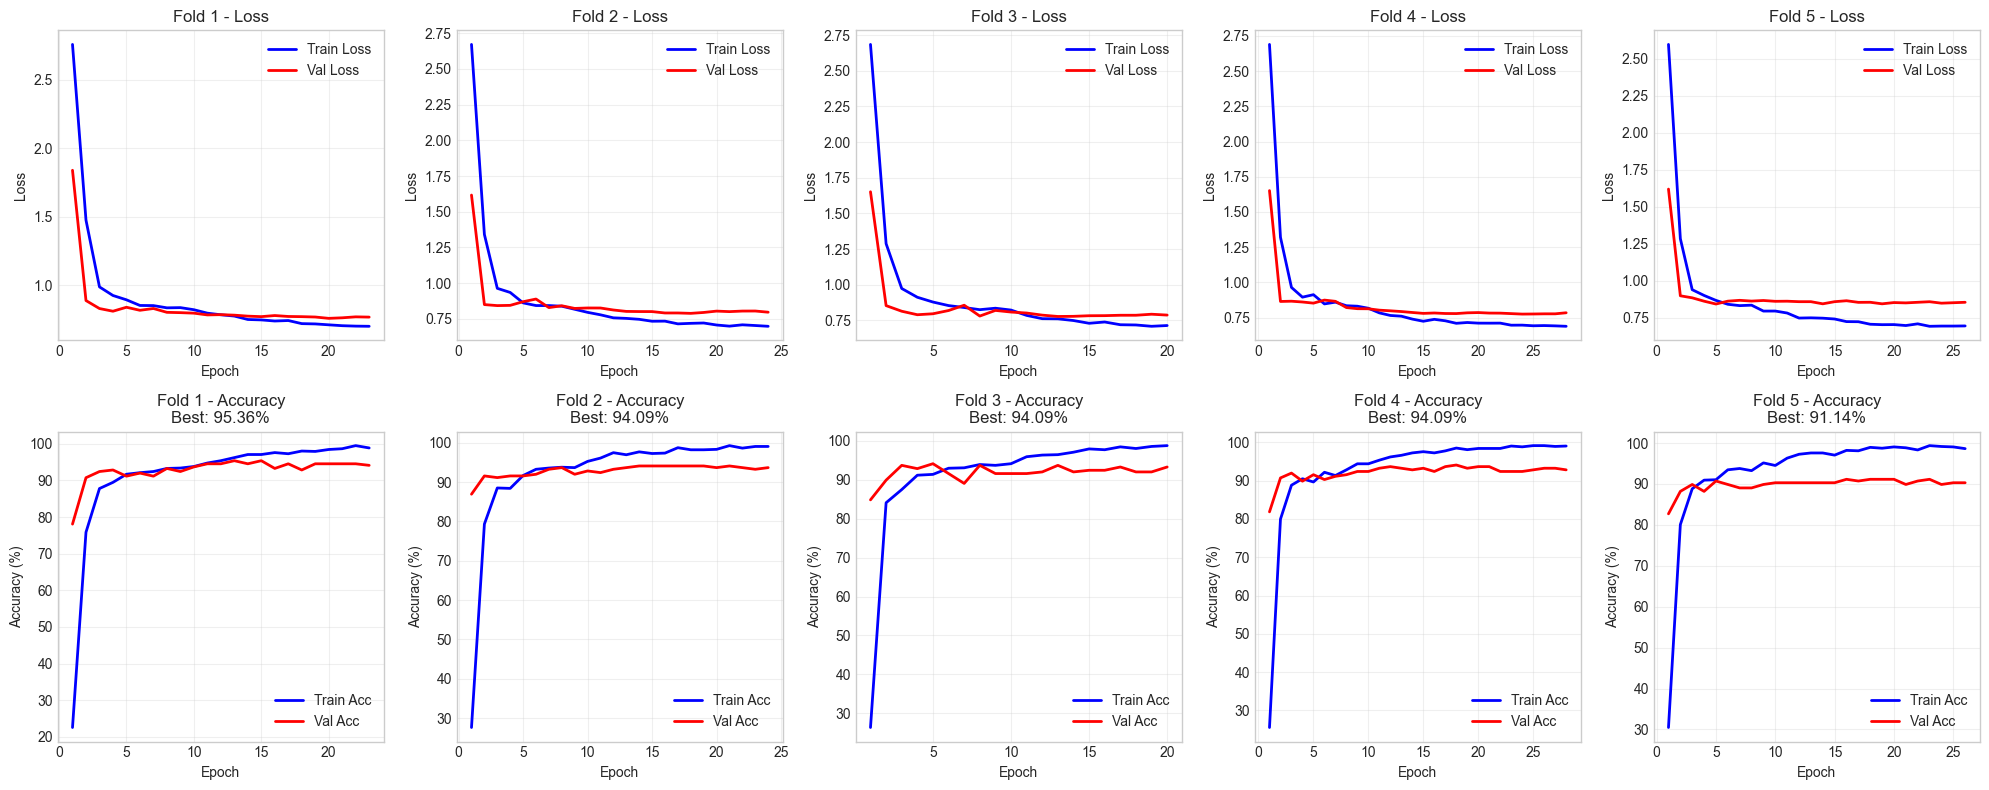

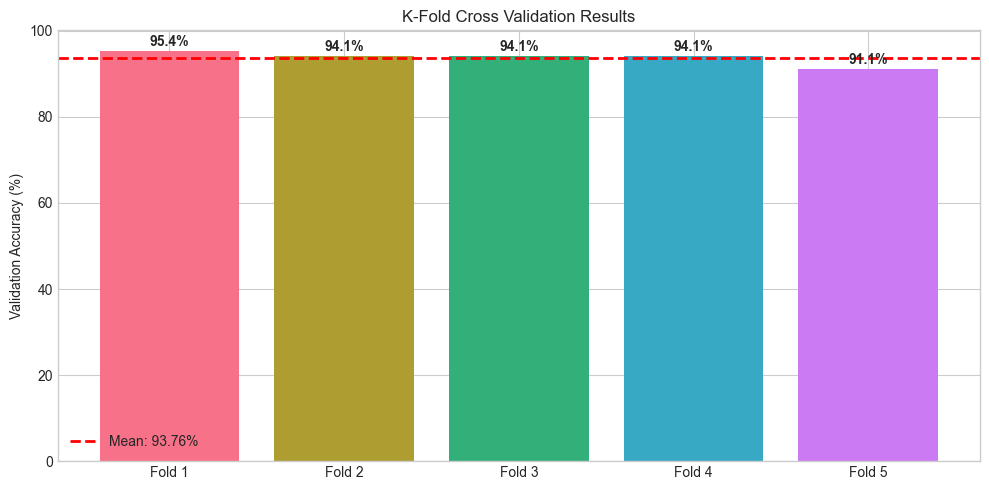

In [14]:
# ============================================
# Visualize Training Results
# ============================================

def plot_training_history(fold_results):
    """Plot training history for all folds"""
    n_folds = len(fold_results)
    
    fig, axes = plt.subplots(2, n_folds, figsize=(4*n_folds, 8))
    
    for fold_idx, result in enumerate(fold_results):
        history = result['history']
        epochs = range(1, len(history['train_loss']) + 1)
        
        # Loss plot
        ax_loss = axes[0, fold_idx] if n_folds > 1 else axes[0]
        ax_loss.plot(epochs, history['train_loss'], 'b-', label='Train Loss', linewidth=2)
        ax_loss.plot(epochs, history['val_loss'], 'r-', label='Val Loss', linewidth=2)
        ax_loss.set_xlabel('Epoch')
        ax_loss.set_ylabel('Loss')
        ax_loss.set_title(f'Fold {fold_idx + 1} - Loss')
        ax_loss.legend()
        ax_loss.grid(True, alpha=0.3)
        
        # Accuracy plot
        ax_acc = axes[1, fold_idx] if n_folds > 1 else axes[1]
        ax_acc.plot(epochs, history['train_acc'], 'b-', label='Train Acc', linewidth=2)
        ax_acc.plot(epochs, history['val_acc'], 'r-', label='Val Acc', linewidth=2)
        ax_acc.set_xlabel('Epoch')
        ax_acc.set_ylabel('Accuracy (%)')
        ax_acc.set_title(f'Fold {fold_idx + 1} - Accuracy\nBest: {result["best_val_acc"]:.2f}%')
        ax_acc.legend()
        ax_acc.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # Summary bar chart
    fig, ax = plt.subplots(figsize=(10, 5))
    folds = [f'Fold {r["fold"]}' for r in fold_results]
    accuracies = [r['best_val_acc'] for r in fold_results]
    
    bars = ax.bar(folds, accuracies, color=sns.color_palette("husl", n_folds))
    ax.axhline(y=np.mean(accuracies), color='red', linestyle='--', 
               label=f'Mean: {np.mean(accuracies):.2f}%', linewidth=2)
    ax.set_ylabel('Validation Accuracy (%)')
    ax.set_title('K-Fold Cross Validation Results')
    ax.legend()
    
    # Add value labels on bars
    for bar, acc in zip(bars, accuracies):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{acc:.1f}%', ha='center', va='bottom', fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('kfold_results.png', dpi=150, bbox_inches='tight')
    plt.show()

# Plot results
plot_training_history(fold_results)

In [15]:
# ============================================
# Test Inference with TTA and Model Ensemble
# ============================================

@torch.no_grad()
def predict_with_tta_ensemble(models, test_dir, config, device):
    """
    Make predictions on test set using:
    1. Ensemble of K-fold models
    2. Test Time Augmentation for each model
    
    Supports two voting methods (configurable):
    - 'mean': Soft voting - average probabilities, then take argmax
    - 'majority': Hard voting - each prediction is a vote, take mode
    """
    from collections import Counter
    
    # Get TTA transforms
    tta_transforms = get_tta_transforms(config)
    n_tta = len(tta_transforms)
    n_models = len(models)
    
    # Get voting methods from config
    tta_voting = getattr(config, 'tta_voting', 'mean')
    ensemble_voting = getattr(config, 'ensemble_voting', 'mean')
    
    # Get test image paths
    test_dir = Path(test_dir)
    test_images = sorted(list(test_dir.glob('*/*.jpg')))
    
    print(f"{'='*60}")
    print(f"TTA Ensemble Prediction Settings:")
    print(f"{'='*60}")
    print(f"  Test images found: {len(test_images)}")
    print(f"  Models in ensemble: {n_models}")
    print(f"  TTA variants: {n_tta}")
    print(f"  Total predictions per image: {n_models * n_tta}")
    print(f"  TTA voting method: {tta_voting}")
    print(f"  Ensemble voting method: {ensemble_voting}")
    print(f"{'='*60}")
    
    all_predictions = []
    all_filenames = []
    
    # Set all models to eval mode
    for model in models:
        model.eval()
    
    pbar = tqdm(test_images, desc='Predicting with TTA Ensemble')
    
    for img_path in pbar:
        image = Image.open(img_path).convert('RGB')
        
        # Collect predictions from all models and all TTA variants
        model_predictions = []  # Store final prediction from each model
        
        for model in models:
            tta_probs = []
            tta_preds = []
            
            for transform in tta_transforms:
                img_tensor = transform(image).unsqueeze(0).to(device)
                output = model(img_tensor)
                probs = torch.softmax(output, dim=1)
                pred = probs.argmax(dim=1).item()
                
                tta_probs.append(probs.cpu())
                tta_preds.append(pred)
            
            # Aggregate TTA predictions for this model
            if tta_voting == 'majority':
                # Hard voting: take the most common prediction across TTA
                vote_counts = Counter(tta_preds)
                model_pred = vote_counts.most_common(1)[0][0]
            else:  # 'mean' (soft voting)
                # Soft voting: average probabilities, then take argmax
                avg_probs = torch.stack(tta_probs).mean(dim=0)
                model_pred = avg_probs.argmax(dim=1).item()
            
            model_predictions.append(model_pred)
        
        # Aggregate ensemble predictions
        if ensemble_voting == 'majority':
            # Hard voting: take the most common prediction across models
            vote_counts = Counter(model_predictions)
            final_pred = vote_counts.most_common(1)[0][0]
        else:  # 'mean' (soft voting)
            # For mean ensemble with majority TTA, we need probabilities
            # If we used majority for TTA, we'll just do majority for ensemble too
            if tta_voting == 'majority':
                # Fall back to majority for ensemble when TTA is majority
                vote_counts = Counter(model_predictions)
                final_pred = vote_counts.most_common(1)[0][0]
            else:
                # Recollect probabilities for soft ensemble voting
                # (This is less efficient but keeps the logic clean)
                ensemble_probs = []
                for model in models:
                    model_probs = []
                    for transform in tta_transforms:
                        img_tensor = transform(image).unsqueeze(0).to(device)
                        output = model(img_tensor)
                        probs = torch.softmax(output, dim=1)
                        model_probs.append(probs.cpu())
                    avg_probs = torch.stack(model_probs).mean(dim=0)
                    ensemble_probs.append(avg_probs)
                final_probs = torch.stack(ensemble_probs).mean(dim=0)
                final_pred = final_probs.argmax(dim=1).item()
        
        all_predictions.append(final_pred)
        all_filenames.append(img_path.name)
    
    return all_predictions, all_filenames

print("TTA Ensemble inference function defined!")
print(f"  Supports voting methods: 'mean' (soft) and 'majority' (hard)")
print(f"  Configure via: config.tta_voting and config.ensemble_voting")

TTA Ensemble inference function defined!
  Supports voting methods: 'mean' (soft) and 'majority' (hard)
  Configure via: config.tta_voting and config.ensemble_voting


In [16]:
# ============================================
# SELECT SPECIFIC FOLDS FOR PREDICTION (Optional)
# ============================================
# By default, all folds are used for ensemble prediction.
# You can select specific folds (e.g., only the best performing ones) here.

def show_fold_summary(fold_results):
    """Display fold results to help with selection"""
    print("=" * 60)
    print("FOLD PERFORMANCE SUMMARY")
    print("=" * 60)
    
    for r in fold_results:
        print(f"  Fold {r['fold']}: Val Acc = {r['selected_val_acc']:.2f}% (Epoch {r['selected_epoch']})")
    
    mean_acc = np.mean([r['selected_val_acc'] for r in fold_results])
    std_acc = np.std([r['selected_val_acc'] for r in fold_results])
    print("=" * 60)
    print(f"  Mean: {mean_acc:.2f}% ± {std_acc:.2f}%")
    print("=" * 60)
    
    # Find best and worst folds
    best_fold = max(fold_results, key=lambda x: x['selected_val_acc'])
    worst_fold = min(fold_results, key=lambda x: x['selected_val_acc'])
    print(f"\n  🏆 Best:  Fold {best_fold['fold']} ({best_fold['selected_val_acc']:.2f}%)")
    print(f"  📉 Worst: Fold {worst_fold['fold']} ({worst_fold['selected_val_acc']:.2f}%)")


def select_folds_for_prediction(fold_models, fold_results, selected_folds=None):
    """
    Select specific folds for prediction.
    
    Args:
        fold_models: List of all trained fold models
        fold_results: List of fold training results
        selected_folds: List of fold numbers to use (1-indexed), e.g., [1, 2, 4]
                       If None, returns all folds
    
    Returns:
        Tuple of (selected_models, selected_results)
    """
    if selected_folds is None:
        print("Using ALL folds for ensemble prediction")
        return fold_models, fold_results
    
    print(f"\n{'=' * 60}")
    print(f"SELECTING SPECIFIC FOLDS: {selected_folds}")
    print(f"{'=' * 60}")
    
    selected_models = []
    selected_results = []
    
    for fold_num in selected_folds:
        idx = fold_num - 1  # Convert to 0-indexed
        if 0 <= idx < len(fold_models):
            selected_models.append(fold_models[idx])
            selected_results.append(fold_results[idx])
            print(f"  ✓ Fold {fold_num}: {fold_results[idx]['selected_val_acc']:.2f}%")
        else:
            print(f"  ✗ Fold {fold_num}: Not found!")
    
    mean_acc = np.mean([r['selected_val_acc'] for r in selected_results])
    print(f"\n  Selected {len(selected_models)} folds")
    print(f"  Expected mean accuracy: {mean_acc:.2f}%")
    print(f"{'=' * 60}")
    
    return selected_models, selected_results


# Show fold summary
show_fold_summary(fold_results)

# ============================================
# CHOOSE YOUR FOLDS HERE
# ============================================
# Option 1: Use all folds (default - comment out selected_folds)
# Option 2: Use specific folds - set the list below

# Set to None to use ALL folds, or specify fold numbers like [1, 2, 4]
USE_FOLDS = None  # e.g., [2, 4] for only folds 2 and 4, or [2] for single best fold

# Apply selection
models_for_prediction, results_for_prediction = select_folds_for_prediction(
    fold_models, 
    fold_results, 
    selected_folds=USE_FOLDS
)

print(f"\n→ Using {len(models_for_prediction)} model(s) for prediction")

FOLD PERFORMANCE SUMMARY
  Fold 1: Val Acc = 95.36% (Epoch 13)
  Fold 2: Val Acc = 94.09% (Epoch 14)
  Fold 3: Val Acc = 94.09% (Epoch 5)
  Fold 4: Val Acc = 94.09% (Epoch 18)
  Fold 5: Val Acc = 91.14% (Epoch 16)
  Mean: 93.76% ± 1.40%

  🏆 Best:  Fold 1 (95.36%)
  📉 Worst: Fold 5 (91.14%)
Using ALL folds for ensemble prediction

→ Using 5 model(s) for prediction


In [17]:
# ============================================
# Generate Predictions on Test Set
# ============================================

# Run TTA ensemble prediction using selected models
# (Use models_for_prediction from the previous cell - can be all folds or selected folds)
predictions, filenames = predict_with_tta_ensemble(
    models_for_prediction,  # Uses selected folds (or all if USE_FOLDS=None)
    TEST_PATH, 
    config, 
    device
)

print(f"\nPredictions generated for {len(predictions)} images")
print(f"Using {len(models_for_prediction)} fold model(s) in ensemble")

TTA Ensemble Prediction Settings:
  Test images found: 400
  Models in ensemble: 5
  TTA variants: 5
  Total predictions per image: 25
  TTA voting method: mean
  Ensemble voting method: mean


Predicting with TTA Ensemble:   0%|          | 0/400 [00:00<?, ?it/s]


Predictions generated for 400 images
Using 5 fold model(s) in ensemble


In [18]:
# ============================================
# Create Submission File
# ============================================

# IMPORTANT: Submission format must match sample_submission.csv
# Column 1: 'path' (the image filename)
# Column 2: 'class_idx' (the numeric class index, NOT class name)

# Create submission dataframe with correct format
submission_df = pd.DataFrame({
    'path': filenames,           # First column: path (image filename)
    'class_idx': predictions      # Second column: class_idx (numeric prediction)
})

# Sort by path to match sample submission format
submission_df = submission_df.sort_values('path').reset_index(drop=True)

# Display sample
print("Submission Preview (correct format: path, class_idx):")
print(submission_df.head(10))

print(f"\nClass index distribution in predictions:")
print(submission_df['class_idx'].value_counts().sort_index())

# Verify format matches sample submission
print(f"\nSubmission columns: {list(submission_df.columns)}")
print(f"Expected columns: ['path', 'class_idx']")

# ============================================
# Generate organized submission folder structure
# ============================================
import os
from datetime import datetime

# Extract model name (short version)
model_short = config.model_name.split('.')[-1].replace('_', '-')  # e.g., 'in21k-ft-in1k'
model_base = config.model_name.split('.')[0].replace('_', '')  # e.g., 'tfefficientnetv2s'
model_arch = config.model_name.split('.')[0].replace('tf_', '').replace('_', '')  # e.g., 'efficientnetv2s'

# Determine training mode
if config.freeze_backbone_always:
    train_mode = 'frozen-always'
elif config.use_transfer_learning:
    if config.unfreeze_all_layers:
        train_mode = 'tl-all-unfrozen'
    else:
        train_mode = f'tl-last{config.unfreeze_last_n_blocks}blocks'
else:
    train_mode = 'full-training'

# Build experiment folder name (same as models)
# Determine voting mode string
voting_mode = f'{config.tta_voting[0]}{config.ensemble_voting[0]}'  # e.g., 'mm' for majority-majority
head_type = getattr(config, 'head_type', 'default')

# Determine folds info for naming
folds_used = [r['fold'] for r in results_for_prediction]
if len(folds_used) == config.n_folds:
    folds_str = f'{config.n_folds}fold'  # All folds
else:
    folds_str = f'fold{"".join(str(f) for f in folds_used)}'  # e.g., 'fold24' for folds 2,4

experiment_parts = [
    f'img{config.img_size}',                       # Image size
    folds_str,                                     # Folds used
    train_mode,                                    # Training mode
]
# Add head type if not default
if head_type != 'default':
    experiment_parts.append(f'head-{head_type}')
experiment_parts.extend([
    f'ep{config.total_epochs}',                    # Total epochs
    f'tta{len(get_tta_transforms(config))}-{voting_mode}',  # TTA variants + voting mode
    datetime.now().strftime('%Y%m%d_%H%M')         # Timestamp
])
experiment_name = '_'.join(experiment_parts)

# Create folder structure: submissions/<model_arch>/<experiment_name>/
submissions_base_dir = 'submissions'
model_arch_dir = os.path.join(submissions_base_dir, model_arch)
experiment_dir = os.path.join(model_arch_dir, experiment_name)

os.makedirs(experiment_dir, exist_ok=True)

# Build filename
submission_filename = 'submission.csv'
submission_path = os.path.join(experiment_dir, submission_filename)

# Save submission
submission_df.to_csv(submission_path, index=False)

# Also save a copy of the config for reference
config_info = {
    'model_name': config.model_name,
    'num_classes': config.num_classes,
    'img_size': config.img_size,
    'batch_size': config.batch_size,
    'head_type': getattr(config, 'head_type', 'default'),
    'head_hidden_dim': getattr(config, 'head_hidden_dim', 512),
    'head_hidden_dim_2': getattr(config, 'head_hidden_dim_2', 256),
    'head_dropout': getattr(config, 'head_dropout', 0.3),
    'use_transfer_learning': config.use_transfer_learning,
    'freeze_backbone_always': config.freeze_backbone_always,
    'freeze_backbone_epochs': config.freeze_backbone_epochs,
    'unfreeze_epochs': config.unfreeze_epochs,
    'unfreeze_all_layers': config.unfreeze_all_layers,
    'unfreeze_last_n_blocks': config.unfreeze_last_n_blocks,
    'learning_rate_head': config.learning_rate_head,
    'learning_rate_backbone': config.learning_rate_backbone,
    'weight_decay': config.weight_decay,
    'n_folds': config.n_folds,
    'total_epochs': config.total_epochs,
    'tta_variants': len(get_tta_transforms(config)),
    'tta_voting': config.tta_voting,
    'ensemble_voting': config.ensemble_voting,
    'train_mode': train_mode,
    'folds_used': [r['fold'] for r in results_for_prediction],  # Which folds were used
    'num_folds_used': len(results_for_prediction),
    'mean_val_accuracy': np.mean([r['best_val_acc'] for r in results_for_prediction]),
    'std_val_accuracy': np.std([r['best_val_acc'] for r in results_for_prediction]),
    'fold_accuracies': [{'fold': r['fold'], 'acc': r['best_val_acc']} for r in results_for_prediction]
}

# Save config as JSON
import json
config_path = os.path.join(experiment_dir, 'experiment_config.json')
with open(config_path, 'w') as f:
    json.dump(config_info, f, indent=2)

print(f"\n{'='*60}")
print(f"Submission Directory Structure:")
print(f"{'='*60}")
print(f"  Base: {submissions_base_dir}/")
print(f"  └── Architecture: {model_arch}/")
print(f"      └── Experiment: {experiment_name}/")
print(f"          ├── submission.csv")
print(f"          └── experiment_config.json")

print(f"\n{'='*60}")
print(f"Submission Details:")
print(f"{'='*60}")
print(f"  Model: {config.model_name}")
print(f"  Image Size: {config.img_size}x{config.img_size}")
print(f"  Folds Used: {folds_used} ({len(folds_used)} of {config.n_folds})")
print(f"  Training Mode: {train_mode}")
print(f"  Total Epochs: {config.total_epochs}")
print(f"  TTA Variants: {len(get_tta_transforms(config))}")
print(f"  Mean Val Accuracy: {config_info['mean_val_accuracy']:.2f}% ± {config_info['std_val_accuracy']:.2f}%")
print(f"\n✓ Submission saved to: {submission_path}")
print(f"✓ Config saved to: {config_path}")

Submission Preview (correct format: path, class_idx):
                                       path  class_idx
0  000c02a0-3687-4c0c-bdfc-394b56134ac6.jpg         13
1  0036f660-7d6e-46d4-822d-dbb71b20c788.jpg         19
2  0082f891-33f6-4057-aa63-c2f462ea66a5.jpg         15
3  01e21934-d737-4992-b712-cf544666bd54.jpg         12
4  0321cf4c-2a19-42b5-992c-f1d6d80af4c7.jpg          3
5  03b3a4cf-dccc-4874-bf30-809e5498a815.jpg         16
6  04ad8917-07dc-451a-a59c-f4fc8827e0ab.jpg          7
7  054c4510-d3a2-4b20-976e-2cf93f78ec81.jpg         13
8  05d54ffe-c3ef-41c8-94eb-44bdd2c77311.jpg         10
9  061c3569-07a0-4611-ad18-ffeec09fb828.jpg         18

Class index distribution in predictions:
class_idx
0     23
1     13
2     16
3     20
4     24
5     18
6     16
7     20
8     17
9     19
10    20
11    19
12    14
13    30
14    19
15    28
16    22
17    17
18    25
19    20
Name: count, dtype: int64

Submission columns: ['path', 'class_idx']
Expected columns: ['path', 'class_idx']


In [17]:
# ============================================
# Save Models (Organized Folder Structure)
# ============================================

import os
import json
from datetime import datetime

# ============================================
# Generate organized folder structure
# ============================================

# Main model folder (architecture name)
model_arch = config.model_name.split('.')[0].replace('tf_', '').replace('_', '')  # e.g., 'efficientnetv2s'

# Determine training mode for subfolder naming
if config.freeze_backbone_always:
    train_mode = 'frozen-always'
elif config.use_transfer_learning:
    if config.unfreeze_all_layers:
        train_mode = 'tl-all-unfrozen'
    else:
        train_mode = f'tl-last{config.unfreeze_last_n_blocks}blocks'
else:
    train_mode = 'full-training'

# Build experiment subfolder name
# Determine voting mode string
voting_mode = f'{config.tta_voting[0]}{config.ensemble_voting[0]}'  # e.g., 'mm' for majority-majority, 'me' for mean-ensemble
head_type = getattr(config, 'head_type', 'default')

experiment_parts = [
    f'img{config.img_size}',                       # Image size
    f'{config.n_folds}fold',                       # Number of folds
    train_mode,                                    # Training mode
]
# Add head type if not default
if head_type != 'default':
    experiment_parts.append(f'head-{head_type}')
experiment_parts.extend([
    f'ep{config.total_epochs}',                    # Total epochs
    f'tta{len(get_tta_transforms(config))}-{voting_mode}',  # TTA variants + voting mode
    datetime.now().strftime('%Y%m%d_%H%M')         # Timestamp
])
experiment_name = '_'.join(experiment_parts)

# Create folder structure: models/<model_arch>/<experiment_name>/
models_base_dir = 'models'
model_arch_dir = os.path.join(models_base_dir, model_arch)
experiment_dir = os.path.join(model_arch_dir, experiment_name)

os.makedirs(experiment_dir, exist_ok=True)

print(f"{'='*60}")
print(f"Model Save Directory Structure:")
print(f"{'='*60}")
print(f"  Base: {models_base_dir}/")
print(f"  └── Architecture: {model_arch}/")
print(f"      └── Experiment: {experiment_name}/")
print(f"{'='*60}")

# ============================================
# Save experiment_config.json (similar to submission)
# ============================================

config_info = {
    'model_name': config.model_name,
    'num_classes': config.num_classes,
    'img_size': config.img_size,
    'batch_size': config.batch_size,
    'head_type': getattr(config, 'head_type', 'default'),
    'head_hidden_dim': getattr(config, 'head_hidden_dim', 512),
    'head_hidden_dim_2': getattr(config, 'head_hidden_dim_2', 256),
    'head_dropout': getattr(config, 'head_dropout', 0.3),
    'use_transfer_learning': config.use_transfer_learning,
    'freeze_backbone_always': config.freeze_backbone_always,
    'freeze_backbone_epochs': config.freeze_backbone_epochs,
    'unfreeze_epochs': config.unfreeze_epochs,
    'unfreeze_all_layers': config.unfreeze_all_layers,
    'unfreeze_last_n_blocks': config.unfreeze_last_n_blocks,
    'learning_rate_head': config.learning_rate_head,
    'learning_rate_backbone': config.learning_rate_backbone,
    'weight_decay': config.weight_decay,
    'n_folds': config.n_folds,
    'total_epochs': config.total_epochs,
    'tta_variants': len(get_tta_transforms(config)),
    'tta_voting': config.tta_voting,
    'ensemble_voting': config.ensemble_voting,
    'checkpoint_strategy': config.checkpoint_strategy,
    'save_all_epochs': config.save_all_epochs,
    'selected_folds': config.selected_folds,
    'train_mode': train_mode,
    'mean_val_accuracy': np.mean([r['selected_val_acc'] for r in fold_results]),
    'std_val_accuracy': np.std([r['selected_val_acc'] for r in fold_results]),
    'fold_details': [
        {
            'fold': r['fold'],
            'best_val_acc': r['best_val_acc'],
            'best_val_epoch': r['best_val_epoch'],
            'last_val_acc': r['last_val_acc'],
            'last_val_epoch': r['last_val_epoch'],
            'selected_val_acc': r['selected_val_acc'],
            'selected_epoch': r['selected_epoch']
        }
        for r in fold_results
    ]
}

config_path = os.path.join(experiment_dir, 'experiment_config.json')
with open(config_path, 'w') as f:
    json.dump(config_info, f, indent=2)
print(f"✓ Saved: {config_path}")

# ============================================
# Save each fold model
# ============================================
for fold_idx, model in enumerate(fold_models):
    model_filename = f'fold{fold_idx + 1}.pth'
    model_path = os.path.join(experiment_dir, model_filename)
    
    fold_result = fold_results[fold_idx]
    
    # Save comprehensive checkpoint
    torch.save({
        'model_state_dict': model.state_dict(),
        'config': {
            'model_name': config.model_name,
            'num_classes': config.num_classes,
            'img_size': config.img_size,
            'batch_size': config.batch_size,
            'head_type': getattr(config, 'head_type', 'default'),
            'head_hidden_dim': getattr(config, 'head_hidden_dim', 512),
            'head_hidden_dim_2': getattr(config, 'head_hidden_dim_2', 256),
            'head_dropout': getattr(config, 'head_dropout', 0.3),
            'head_use_batchnorm': getattr(config, 'head_use_batchnorm', True),
            'use_transfer_learning': config.use_transfer_learning,
            'freeze_backbone_always': config.freeze_backbone_always,
            'freeze_backbone_epochs': config.freeze_backbone_epochs,
            'unfreeze_epochs': config.unfreeze_epochs,
            'unfreeze_all_layers': config.unfreeze_all_layers,
            'unfreeze_last_n_blocks': config.unfreeze_last_n_blocks,
            'learning_rate_head': config.learning_rate_head,
            'learning_rate_backbone': config.learning_rate_backbone,
            'weight_decay': config.weight_decay,
            'n_folds': config.n_folds,
            'total_epochs': config.total_epochs,
            'tta_voting': config.tta_voting,
            'ensemble_voting': config.ensemble_voting,
            'checkpoint_strategy': config.checkpoint_strategy,
            'save_all_epochs': config.save_all_epochs
        },
        'class_mapping': class_mapping,
        'fold': fold_idx + 1,
        'best_val_acc': fold_result['best_val_acc'],
        'best_val_epoch': fold_result['best_val_epoch'],
        'last_val_acc': fold_result['last_val_acc'],
        'last_val_epoch': fold_result['last_val_epoch'],
        'selected_val_acc': fold_result['selected_val_acc'],
        'selected_epoch': fold_result['selected_epoch'],
        'checkpoint_strategy': fold_result['checkpoint_strategy'],
        'history': fold_result['history']
    }, model_path)
    print(f"✓ Saved: {model_path} (Selected Val Acc: {fold_result['selected_val_acc']:.2f}%, Epoch {fold_result['selected_epoch']})")

# ============================================
# Save all epoch checkpoints if enabled
# ============================================
if config.save_all_epochs:
    checkpoints_dir = os.path.join(experiment_dir, 'epoch_checkpoints')
    os.makedirs(checkpoints_dir, exist_ok=True)
    
    print(f"\n{'='*60}")
    print(f"Saving all epoch checkpoints...")
    print(f"{'='*60}")
    
    for fold_idx, fold_result in enumerate(fold_results):
        if fold_result['epoch_checkpoints'] is not None:
            fold_checkpoint_dir = os.path.join(checkpoints_dir, f'fold{fold_idx + 1}')
            os.makedirs(fold_checkpoint_dir, exist_ok=True)
            
            for checkpoint in fold_result['epoch_checkpoints']:
                epoch_filename = f'epoch{checkpoint["epoch"]}.pth'
                epoch_path = os.path.join(fold_checkpoint_dir, epoch_filename)
                
                torch.save({
                    'model_state_dict': checkpoint['model_state_dict'],
                    'epoch': checkpoint['epoch'],
                    'val_acc': checkpoint['val_acc'],
                    'train_acc': checkpoint['train_acc'],
                    'val_loss': checkpoint['val_loss'],
                    'train_loss': checkpoint['train_loss'],
                    'stage': checkpoint['stage'],
                    'fold': fold_idx + 1,
                    'config': {
                        'model_name': config.model_name,
                        'num_classes': config.num_classes,
                        'img_size': config.img_size,
                        'head_type': getattr(config, 'head_type', 'default'),
                        'head_hidden_dim': getattr(config, 'head_hidden_dim', 512),
                        'head_hidden_dim_2': getattr(config, 'head_hidden_dim_2', 256),
                        'head_dropout': getattr(config, 'head_dropout', 0.3),
                        'head_use_batchnorm': getattr(config, 'head_use_batchnorm', True)
                    },
                    'class_mapping': class_mapping
                }, epoch_path)
            
            print(f"  Fold {fold_idx + 1}: {len(fold_result['epoch_checkpoints'])} epoch checkpoints saved")
    
    print(f"  Location: {checkpoints_dir}/")

# Calculate mean accuracy
mean_acc = np.mean([r['selected_val_acc'] for r in fold_results])
std_acc = np.std([r['selected_val_acc'] for r in fold_results])
best_mean_acc = np.mean([r['best_val_acc'] for r in fold_results])
best_std_acc = np.std([r['best_val_acc'] for r in fold_results])

print(f"\n{'='*60}")
print(f"Summary:")
print(f"{'='*60}")
print(f"  Models saved: {len(fold_models)}")
print(f"  Location: {experiment_dir}/")
print(f"  Checkpoint strategy: {config.checkpoint_strategy}")
print(f"  Best Mean Accuracy: {best_mean_acc:.2f}% ± {best_std_acc:.2f}%")
print(f"  Selected Mean Accuracy: {mean_acc:.2f}% ± {std_acc:.2f}%")
if config.save_all_epochs:
    print(f"  All epoch checkpoints saved: Yes")
print(f"{'='*60}")

Model Save Directory Structure:
  Base: models/
  └── Architecture: convnexttiny/
      └── Experiment: img384_5fold_tl-last2blocks_head-mlp_ep30_tta5-mm_20260201_1405/
✓ Saved: models/convnexttiny/img384_5fold_tl-last2blocks_head-mlp_ep30_tta5-mm_20260201_1405/experiment_config.json
✓ Saved: models/convnexttiny/img384_5fold_tl-last2blocks_head-mlp_ep30_tta5-mm_20260201_1405/fold1.pth (Selected Val Acc: 95.36%, Epoch 13)
✓ Saved: models/convnexttiny/img384_5fold_tl-last2blocks_head-mlp_ep30_tta5-mm_20260201_1405/fold2.pth (Selected Val Acc: 94.09%, Epoch 14)
✓ Saved: models/convnexttiny/img384_5fold_tl-last2blocks_head-mlp_ep30_tta5-mm_20260201_1405/fold3.pth (Selected Val Acc: 94.09%, Epoch 5)
✓ Saved: models/convnexttiny/img384_5fold_tl-last2blocks_head-mlp_ep30_tta5-mm_20260201_1405/fold4.pth (Selected Val Acc: 94.09%, Epoch 18)
✓ Saved: models/convnexttiny/img384_5fold_tl-last2blocks_head-mlp_ep30_tta5-mm_20260201_1405/fold5.pth (Selected Val Acc: 91.14%, Epoch 16)

Saving all epoc

KeyboardInterrupt: 

In [18]:
# ============================================
# Utility: Load Saved Models (Updated for new folder structure)
# ============================================

def list_available_experiments(models_base_dir='models', show_details=True):
    """
    List all available experiment folders with detailed fold information
    
    Args:
        models_base_dir: Base directory for models
        show_details: If True, show detailed fold information
    
    Returns:
        List of experiment directory paths
    """
    models_base = Path(models_base_dir)
    
    if not models_base.exists():
        print(f"No models directory found at: {models_base_dir}")
        return []
    
    experiments = []
    print(f"{'='*80}")
    print(f"Available Experiments:")
    print(f"{'='*80}")
    
    # Iterate through model architectures
    for arch_dir in sorted(models_base.iterdir()):
        if arch_dir.is_dir():
            print(f"\n📁 {arch_dir.name}/")
            
            # Iterate through experiments
            for exp_dir in sorted(arch_dir.iterdir()):
                if exp_dir.is_dir():
                    # Count fold files
                    fold_files = list(exp_dir.glob('fold*.pth'))
                    
                    # Try to load experiment config
                    config_path = exp_dir / 'experiment_config.json'
                    if config_path.exists():
                        import json
                        with open(config_path, 'r') as f:
                            exp_config = json.load(f)
                        
                        mean_acc = exp_config.get('mean_val_accuracy', 0)
                        strategy = exp_config.get('checkpoint_strategy', 'best')
                        print(f"   └── 📂 {exp_dir.name}/")
                        print(f"       Folds: {len(fold_files)}, Strategy: {strategy}, Mean Acc: {mean_acc:.2f}%")
                        
                        if show_details and 'fold_details' in exp_config:
                            for fold in exp_config['fold_details']:
                                print(f"         Fold {fold['fold']}: Best={fold['best_val_acc']:.2f}% (ep{fold['best_val_epoch']}), "
                                      f"Last={fold['last_val_acc']:.2f}% (ep{fold['last_val_epoch']}), "
                                      f"Selected={fold['selected_val_acc']:.2f}%")
                    else:
                        # Fallback: try to get info from first fold
                        acc_str = ""
                        if fold_files:
                            try:
                                checkpoint = torch.load(fold_files[0], map_location='cpu', weights_only=False)
                                acc_str = f", Acc: {checkpoint.get('selected_val_acc', checkpoint.get('val_acc', 'N/A'))}"
                            except:
                                pass
                        print(f"   └── 📂 {exp_dir.name}/ [{len(fold_files)} folds{acc_str}]")
                    
                    experiments.append(str(exp_dir))
    
    print(f"\n{'='*80}")
    return experiments


def load_saved_models(experiment_dir, selected_folds=None, device=device):
    """
    Load saved fold models from an experiment directory
    
    Args:
        experiment_dir: Path to experiment folder
        selected_folds: List of fold numbers to load (e.g., [1, 3, 5]). None = load all folds.
        device: Device to load models on
    
    Returns:
        Tuple of (loaded_models, fold_info_list)
    """
    experiment_path = Path(experiment_dir)
    
    if not experiment_path.exists():
        raise FileNotFoundError(f"Experiment directory not found: {experiment_dir}")
    
    # Find all fold files
    all_fold_files = sorted(experiment_path.glob('fold*.pth'))
    
    if not all_fold_files:
        raise FileNotFoundError(f"No fold*.pth files found in: {experiment_dir}")
    
    # Filter by selected folds if specified
    if selected_folds is not None:
        model_files = [f for f in all_fold_files if int(f.stem.replace('fold', '')) in selected_folds]
        if not model_files:
            raise ValueError(f"No matching folds found for: {selected_folds}")
    else:
        model_files = all_fold_files
    
    loaded_models = []
    fold_info_list = []
    
    print(f"{'='*60}")
    print(f"Loading models from: {experiment_dir}")
    if selected_folds:
        print(f"Selected folds: {selected_folds}")
    print(f"{'='*60}")
    
    for model_path in model_files:
        checkpoint = torch.load(model_path, map_location=device, weights_only=False)
        ckpt_config = checkpoint['config']
        
        # Create model with correct head type
        head_type = ckpt_config.get('head_type', 'default')
        
        if head_type == 'default':
            # Default timm head
            model = timm.create_model(
                ckpt_config['model_name'],
                pretrained=False,
                num_classes=ckpt_config['num_classes']
            )
        else:
            # Custom head - create model without classifier first
            model = timm.create_model(
                ckpt_config['model_name'],
                pretrained=False,
                num_classes=0
            )
            in_features = model.num_features
            
            # Build custom head based on saved config
            num_classes = ckpt_config['num_classes']
            hidden_dim = ckpt_config.get('head_hidden_dim', 512)
            hidden_dim_2 = ckpt_config.get('head_hidden_dim_2', 256)
            dropout = ckpt_config.get('head_dropout', 0.3)
            use_bn = ckpt_config.get('head_use_batchnorm', True)
            
            if head_type == 'mlp':
                layers = [nn.Linear(in_features, hidden_dim)]
                if use_bn:
                    layers.append(nn.BatchNorm1d(hidden_dim))
                layers.extend([nn.ReLU(inplace=True), nn.Dropout(p=dropout), nn.Linear(hidden_dim, num_classes)])
                custom_head = nn.Sequential(*layers)
            elif head_type == 'mlp_deep':
                layers = [nn.Linear(in_features, hidden_dim)]
                if use_bn:
                    layers.append(nn.BatchNorm1d(hidden_dim))
                layers.extend([nn.ReLU(inplace=True), nn.Dropout(p=dropout), nn.Linear(hidden_dim, hidden_dim_2)])
                if use_bn:
                    layers.append(nn.BatchNorm1d(hidden_dim_2))
                layers.extend([nn.ReLU(inplace=True), nn.Dropout(p=dropout), nn.Linear(hidden_dim_2, num_classes)])
                custom_head = nn.Sequential(*layers)
            
            attach_classifier_head(model, custom_head)
            model.num_classes = num_classes
        
        # Load weights
        model.load_state_dict(checkpoint['model_state_dict'])
        model = model.to(device)
        model.eval()
        
        loaded_models.append(model)
        
        fold_info = {
            'fold': checkpoint['fold'],
            'selected_val_acc': checkpoint.get('selected_val_acc', checkpoint.get('val_acc')),
            'selected_epoch': checkpoint.get('selected_epoch', 'N/A'),
            'best_val_acc': checkpoint.get('best_val_acc', checkpoint.get('val_acc')),
            'best_val_epoch': checkpoint.get('best_val_epoch', 'N/A'),
            'checkpoint_strategy': checkpoint.get('checkpoint_strategy', 'best')
        }
        fold_info_list.append(fold_info)
        
        print(f"✓ Loaded: {model_path.name} (Fold {fold_info['fold']}, "
              f"Val Acc: {fold_info['selected_val_acc']:.2f}%, Epoch {fold_info['selected_epoch']})")
    
    # Print experiment config
    print(f"\n{'='*60}")
    print(f"Experiment Config:")
    print(f"{'='*60}")
    config_info = checkpoint['config']
    print(f"  Model: {config_info['model_name']}")
    print(f"  Image Size: {config_info['img_size']}x{config_info['img_size']}")
    print(f"  Checkpoint Strategy: {config_info.get('checkpoint_strategy', 'best')}")
    print(f"  Loaded Folds: {[f['fold'] for f in fold_info_list]}")
    print(f"{'='*60}")
    
    return loaded_models, fold_info_list


def load_epoch_checkpoint(experiment_dir, fold, epoch, device=device):
    """
    Load a specific epoch checkpoint for a fold
    
    Args:
        experiment_dir: Path to experiment folder
        fold: Fold number (1-indexed)
        epoch: Epoch number to load
        device: Device to load model on
    
    Returns:
        Loaded model
    """
    experiment_path = Path(experiment_dir)
    checkpoint_path = experiment_path / 'epoch_checkpoints' / f'fold{fold}' / f'epoch{epoch}.pth'
    
    if not checkpoint_path.exists():
        raise FileNotFoundError(f"Epoch checkpoint not found: {checkpoint_path}")
    
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    ckpt_config = checkpoint['config']
    
    # Create model with correct head type
    head_type = ckpt_config.get('head_type', 'default')
    
    if head_type == 'default':
        model = timm.create_model(
            ckpt_config['model_name'],
            pretrained=False,
            num_classes=ckpt_config['num_classes']
        )
    else:
        # Custom head
        model = timm.create_model(
            ckpt_config['model_name'],
            pretrained=False,
            num_classes=0
        )
        in_features = model.num_features
        num_classes = ckpt_config['num_classes']
        hidden_dim = ckpt_config.get('head_hidden_dim', 512)
        hidden_dim_2 = ckpt_config.get('head_hidden_dim_2', 256)
        dropout = ckpt_config.get('head_dropout', 0.3)
        use_bn = ckpt_config.get('head_use_batchnorm', True)
        
        if head_type == 'mlp':
            layers = [nn.Linear(in_features, hidden_dim)]
            if use_bn:
                layers.append(nn.BatchNorm1d(hidden_dim))
            layers.extend([nn.ReLU(inplace=True), nn.Dropout(p=dropout), nn.Linear(hidden_dim, num_classes)])
            custom_head = nn.Sequential(*layers)
        elif head_type == 'mlp_deep':
            layers = [nn.Linear(in_features, hidden_dim)]
            if use_bn:
                layers.append(nn.BatchNorm1d(hidden_dim))
            layers.extend([nn.ReLU(inplace=True), nn.Dropout(p=dropout), nn.Linear(hidden_dim, hidden_dim_2)])
            if use_bn:
                layers.append(nn.BatchNorm1d(hidden_dim_2))
            layers.extend([nn.ReLU(inplace=True), nn.Dropout(p=dropout), nn.Linear(hidden_dim_2, num_classes)])
            custom_head = nn.Sequential(*layers)
        
        attach_classifier_head(model, custom_head)
        model.num_classes = num_classes
    
    # Load weights
    model.load_state_dict(checkpoint['model_state_dict'])
    model = model.to(device)
    model.eval()
    
    print(f"✓ Loaded: Fold {fold}, Epoch {epoch}")
    print(f"  Val Acc: {checkpoint['val_acc']:.2f}%, Train Acc: {checkpoint['train_acc']:.2f}%")
    print(f"  Stage: {checkpoint['stage']}")
    if head_type != 'default':
        print(f"  Head: {head_type}")
    
    return model


def list_epoch_checkpoints(experiment_dir):
    """
    List all available epoch checkpoints for an experiment
    
    Args:
        experiment_dir: Path to experiment folder
    
    Returns:
        Dictionary mapping fold -> list of (epoch, val_acc) tuples
    """
    experiment_path = Path(experiment_dir)
    checkpoints_dir = experiment_path / 'epoch_checkpoints'
    
    if not checkpoints_dir.exists():
        print(f"No epoch checkpoints found in: {experiment_dir}")
        print("Enable save_all_epochs=True in config to save epoch checkpoints.")
        return {}
    
    epoch_info = {}
    
    print(f"{'='*60}")
    print(f"Available Epoch Checkpoints:")
    print(f"{'='*60}")
    
    for fold_dir in sorted(checkpoints_dir.iterdir()):
        if fold_dir.is_dir():
            fold_num = int(fold_dir.name.replace('fold', ''))
            epoch_info[fold_num] = []
            
            print(f"\nFold {fold_num}:")
            
            for epoch_file in sorted(fold_dir.glob('epoch*.pth')):
                try:
                    checkpoint = torch.load(epoch_file, map_location='cpu', weights_only=False)
                    epoch_num = checkpoint['epoch']
                    val_acc = checkpoint['val_acc']
                    stage = checkpoint['stage']
                    
                    epoch_info[fold_num].append((epoch_num, val_acc, stage))
                    print(f"  Epoch {epoch_num}: Val Acc {val_acc:.2f}% [{stage}]")
                except Exception as e:
                    print(f"  Error loading {epoch_file.name}: {e}")
    
    print(f"\n{'='*60}")
    return epoch_info


def create_custom_ensemble(experiment_dir, fold_epoch_mapping, device=device):
    """
    Create a custom ensemble by selecting specific epochs for each fold
    
    Args:
        experiment_dir: Path to experiment folder
        fold_epoch_mapping: Dictionary mapping fold number to epoch to use
                           e.g., {1: 5, 2: 7, 3: 4, 4: 6, 5: 5}
        device: Device to load models on
    
    Returns:
        List of loaded models
    """
    models = []
    
    print(f"{'='*60}")
    print(f"Creating Custom Ensemble:")
    print(f"{'='*60}")
    
    for fold, epoch in sorted(fold_epoch_mapping.items()):
        model = load_epoch_checkpoint(experiment_dir, fold, epoch, device)
        models.append(model)
    
    print(f"\n✓ Custom ensemble created with {len(models)} models")
    return models


# Example usage:
print("Utility functions defined!")
print("\n" + "="*60)
print("Usage Examples:")
print("="*60)
print("""
1. List all experiments with fold details:
   list_available_experiments('models')

2. Load all fold models:
   models, fold_info = load_saved_models('models/efficientnetv2s/exp_name/')

3. Load only specific folds (manual selection):
   models, fold_info = load_saved_models('models/efficientnetv2s/exp_name/', selected_folds=[1, 3, 5])

4. List available epoch checkpoints:
   epoch_info = list_epoch_checkpoints('models/efficientnetv2s/exp_name/')

5. Load a specific epoch checkpoint:
   model = load_epoch_checkpoint('models/efficientnetv2s/exp_name/', fold=1, epoch=5)

6. Create custom ensemble with specific epochs per fold:
   custom_models = create_custom_ensemble('models/efficientnetv2s/exp_name/', 
                                          {1: 5, 2: 7, 3: 4, 4: 6, 5: 5})

7. Run predictions with loaded models:
   predictions, filenames = predict_with_tta_ensemble(models, TEST_PATH, config, device)
""")

Utility functions defined!

Usage Examples:

1. List all experiments with fold details:
   list_available_experiments('models')

2. Load all fold models:
   models, fold_info = load_saved_models('models/efficientnetv2s/exp_name/')

3. Load only specific folds (manual selection):
   models, fold_info = load_saved_models('models/efficientnetv2s/exp_name/', selected_folds=[1, 3, 5])

4. List available epoch checkpoints:
   epoch_info = list_epoch_checkpoints('models/efficientnetv2s/exp_name/')

5. Load a specific epoch checkpoint:
   model = load_epoch_checkpoint('models/efficientnetv2s/exp_name/', fold=1, epoch=5)

6. Create custom ensemble with specific epochs per fold:
   custom_models = create_custom_ensemble('models/efficientnetv2s/exp_name/', 
                                          {1: 5, 2: 7, 3: 4, 4: 6, 5: 5})

7. Run predictions with loaded models:
   predictions, filenames = predict_with_tta_ensemble(models, TEST_PATH, config, device)



In [19]:
# ============================================
# Interactive Epoch Selection Workflow
# ============================================
# Use this AFTER training to review fold histories and select specific epochs

def display_fold_training_history(fold_results):
    """
    Display detailed training history for each fold to help choose epochs
    
    Args:
        fold_results: Results from train_kfold()
    """
    print("="*80)
    print("TRAINING HISTORY - Review and Select Epochs")
    print("="*80)
    
    for result in fold_results:
        fold = result['fold']
        history = result['history']
        best_epoch = result['best_val_epoch']
        best_acc = result['best_val_acc']
        
        print(f"\n{'='*80}")
        print(f"FOLD {fold}")
        print(f"{'='*80}")
        print(f"{'Epoch':<8} {'Stage':<12} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12} {'Note'}")
        print("-"*80)
        
        for i in range(len(history['epoch'])):
            epoch = history['epoch'][i]
            stage = history['stage'][i]
            train_loss = history['train_loss'][i]
            train_acc = history['train_acc'][i]
            val_loss = history['val_loss'][i]
            val_acc = history['val_acc'][i]
            
            # Mark best epoch
            note = "⭐ BEST" if epoch == best_epoch else ""
            
            print(f"{epoch:<8} {stage:<12} {train_loss:<12.4f} {train_acc:<12.2f} {val_loss:<12.4f} {val_acc:<12.2f} {note}")
        
        print(f"\n  Best Epoch: {best_epoch} (Val Acc: {best_acc:.2f}%)")
        print(f"  Last Epoch: {history['epoch'][-1]} (Val Acc: {history['val_acc'][-1]:.2f}%)")


def plot_fold_histories(fold_results, show_selection=None):
    """
    Plot training curves for all folds with optional epoch selection markers
    
    Args:
        fold_results: Results from train_kfold()
        show_selection: Optional dict {fold: epoch} to mark selected epochs
    """
    n_folds = len(fold_results)
    fig, axes = plt.subplots(2, n_folds, figsize=(5*n_folds, 8))
    
    for fold_idx, result in enumerate(fold_results):
        fold = result['fold']
        history = result['history']
        epochs = history['epoch']
        best_epoch = result['best_val_epoch']
        
        # Loss plot
        ax_loss = axes[0, fold_idx] if n_folds > 1 else axes[0]
        ax_loss.plot(epochs, history['train_loss'], 'b-', label='Train', linewidth=2)
        ax_loss.plot(epochs, history['val_loss'], 'r-', label='Val', linewidth=2)
        ax_loss.axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best (ep{best_epoch})')
        
        if show_selection and fold in show_selection:
            ax_loss.axvline(x=show_selection[fold], color='purple', linestyle='-', linewidth=2, label=f'Selected (ep{show_selection[fold]})')
        
        ax_loss.set_xlabel('Epoch')
        ax_loss.set_ylabel('Loss')
        ax_loss.set_title(f'Fold {fold} - Loss')
        ax_loss.legend(fontsize=8)
        ax_loss.grid(True, alpha=0.3)
        
        # Accuracy plot
        ax_acc = axes[1, fold_idx] if n_folds > 1 else axes[1]
        ax_acc.plot(epochs, history['train_acc'], 'b-', label='Train', linewidth=2)
        ax_acc.plot(epochs, history['val_acc'], 'r-', label='Val', linewidth=2)
        ax_acc.axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best (ep{best_epoch})')
        
        if show_selection and fold in show_selection:
            ax_acc.axvline(x=show_selection[fold], color='purple', linestyle='-', linewidth=2, label=f'Selected (ep{show_selection[fold]})')
        
        ax_acc.set_xlabel('Epoch')
        ax_acc.set_ylabel('Accuracy (%)')
        ax_acc.set_title(f'Fold {fold} - Val Acc: {result["best_val_acc"]:.1f}%')
        ax_acc.legend(fontsize=8)
        ax_acc.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


def get_epoch_models_from_results(fold_results, epoch_selection, device=device):
    """
    Get models from specific epochs using saved epoch_checkpoints from training results
    (Only works if save_all_epochs=True was set during training)
    
    Args:
        fold_results: Results from train_kfold() with epoch_checkpoints
        epoch_selection: Dict {fold: epoch} specifying which epoch to use per fold
        device: Device to load models on
    
    Returns:
        List of models with selected epochs
    """
    models = []
    
    print(f"{'='*60}")
    print(f"Creating Ensemble from Training Results:")
    print(f"{'='*60}")
    
    for result in fold_results:
        fold = result['fold']
        
        if fold not in epoch_selection:
            print(f"  Fold {fold}: Skipped (not in selection)")
            continue
        
        target_epoch = epoch_selection[fold]
        
        if result['epoch_checkpoints'] is None:
            print(f"  Fold {fold}: ❌ No epoch checkpoints saved (enable save_all_epochs=True)")
            continue
        
        # Find the checkpoint for the target epoch
        checkpoint = None
        for cp in result['epoch_checkpoints']:
            if cp['epoch'] == target_epoch:
                checkpoint = cp
                break
        
        if checkpoint is None:
            print(f"  Fold {fold}: ❌ Epoch {target_epoch} not found")
            continue
        
        # Create model with correct head type
        head_type = getattr(config, 'head_type', 'default')
        
        if head_type == 'default':
            model = timm.create_model(
                config.model_name,
                pretrained=False,
                num_classes=config.num_classes
            )
        else:
            # Custom head
            model = timm.create_model(
                config.model_name,
                pretrained=False,
                num_classes=0
            )
            in_features = model.num_features
            custom_head = build_classifier_head(in_features, config)
            attach_classifier_head(model, custom_head)
            model.num_classes = config.num_classes
        
        model.load_state_dict(checkpoint['model_state_dict'])
        model = model.to(device)
        model.eval()
        
        models.append(model)
        print(f"  Fold {fold}: ✓ Epoch {target_epoch} (Val Acc: {checkpoint['val_acc']:.2f}%)")
    
    print(f"\n✓ Ensemble created with {len(models)} models")
    return models


print("Interactive epoch selection functions defined!")
print("""
WORKFLOW AFTER TRAINING:
========================

Step 1: Review training history
   display_fold_training_history(fold_results)

Step 2: Visualize training curves
   plot_fold_histories(fold_results)

Step 3: Define your epoch selection
   my_selection = {
       1: 4,  # Fold 1: use epoch 4
       2: 5,  # Fold 2: use epoch 5
       3: 3,  # Fold 3: use epoch 3
       4: 6,  # Fold 4: use epoch 6
       5: 4   # Fold 5: use epoch 4
   }

Step 4: Visualize with your selection
   plot_fold_histories(fold_results, show_selection=my_selection)

Step 5: Create ensemble with selected epochs
   # If you have epoch_checkpoints saved during training:
   selected_models = get_epoch_models_from_results(fold_results, my_selection, device)
   
   # Or if loading from saved files:
   selected_models = create_custom_ensemble('models/efficientnetv2s/exp_name/', my_selection, device)

Step 6: Run predictions
   predictions, filenames = predict_with_tta_ensemble(selected_models, TEST_PATH, config, device)
""")

Interactive epoch selection functions defined!

WORKFLOW AFTER TRAINING:

Step 1: Review training history
   display_fold_training_history(fold_results)

Step 2: Visualize training curves
   plot_fold_histories(fold_results)

Step 3: Define your epoch selection
   my_selection = {
       1: 4,  # Fold 1: use epoch 4
       2: 5,  # Fold 2: use epoch 5
       3: 3,  # Fold 3: use epoch 3
       4: 6,  # Fold 4: use epoch 6
       5: 4   # Fold 5: use epoch 4
   }

Step 4: Visualize with your selection
   plot_fold_histories(fold_results, show_selection=my_selection)

Step 5: Create ensemble with selected epochs
   # If you have epoch_checkpoints saved during training:
   selected_models = get_epoch_models_from_results(fold_results, my_selection, device)
   
   # Or if loading from saved files:
   selected_models = create_custom_ensemble('models/efficientnetv2s/exp_name/', my_selection, device)

Step 6: Run predictions
   predictions, filenames = predict_with_tta_ensemble(selected_models

TRAINING HISTORY - Review and Select Epochs

FOLD 1
Epoch    Stage        Train Loss   Train Acc    Val Loss     Val Acc      Note
--------------------------------------------------------------------------------
1        Frozen       2.7593       22.57        1.8392       78.06        
2        Frozen       1.4751       75.84        0.8868       90.72        
3        Frozen       0.9866       87.76        0.8284       92.41        
4        Frozen       0.9238       89.45        0.8089       92.83        
5        Frozen       0.8922       91.67        0.8378       91.14        
6        Frozen       0.8509       92.09        0.8156       91.98        
7        Frozen       0.8499       92.41        0.8287       91.14        
8        Frozen       0.8336       93.25        0.8007       93.25        
9        Frozen       0.8351       93.35        0.7984       92.41        
10       Frozen       0.8198       93.78        0.7947       93.67        
11       Fine-tune    0.7946       94.

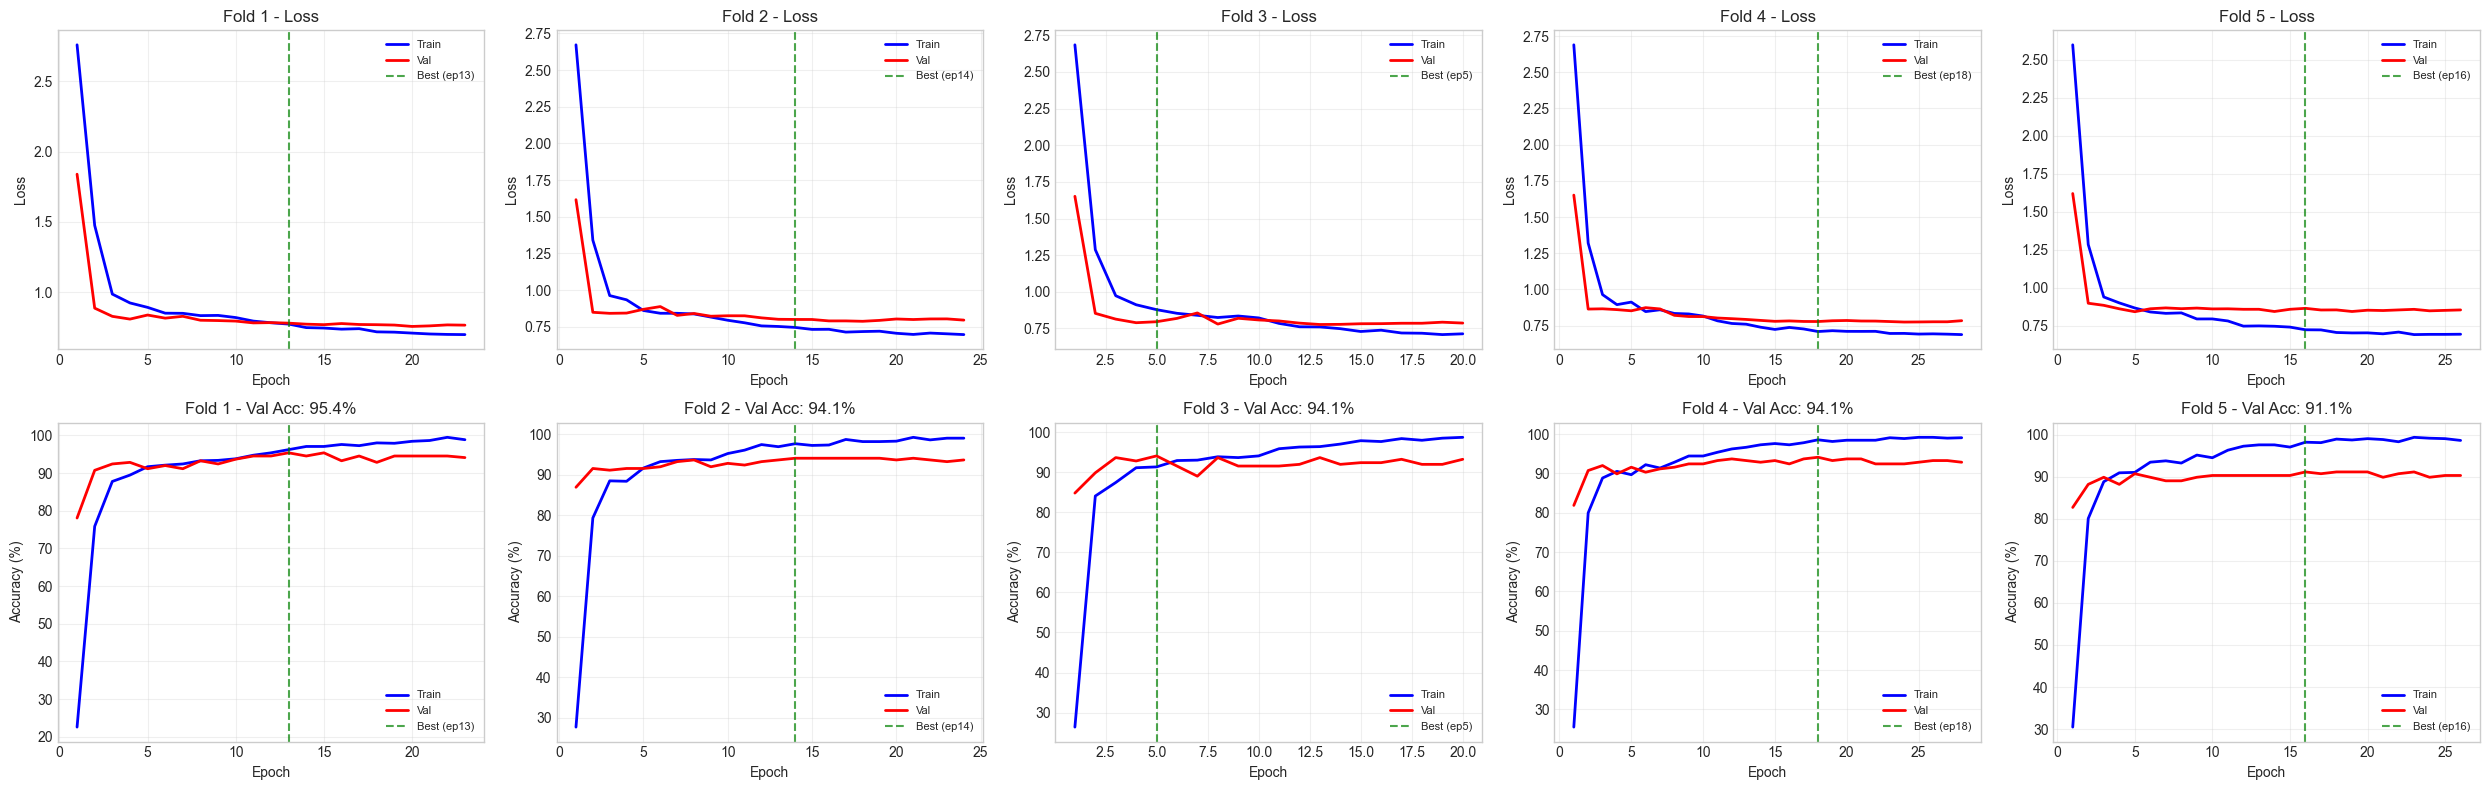

In [20]:
# ============================================
# STEP 1: Review Training History (Run after training)
# ============================================

# Display detailed epoch-by-epoch results
display_fold_training_history(fold_results)

# Visualize training curves
plot_fold_histories(fold_results)

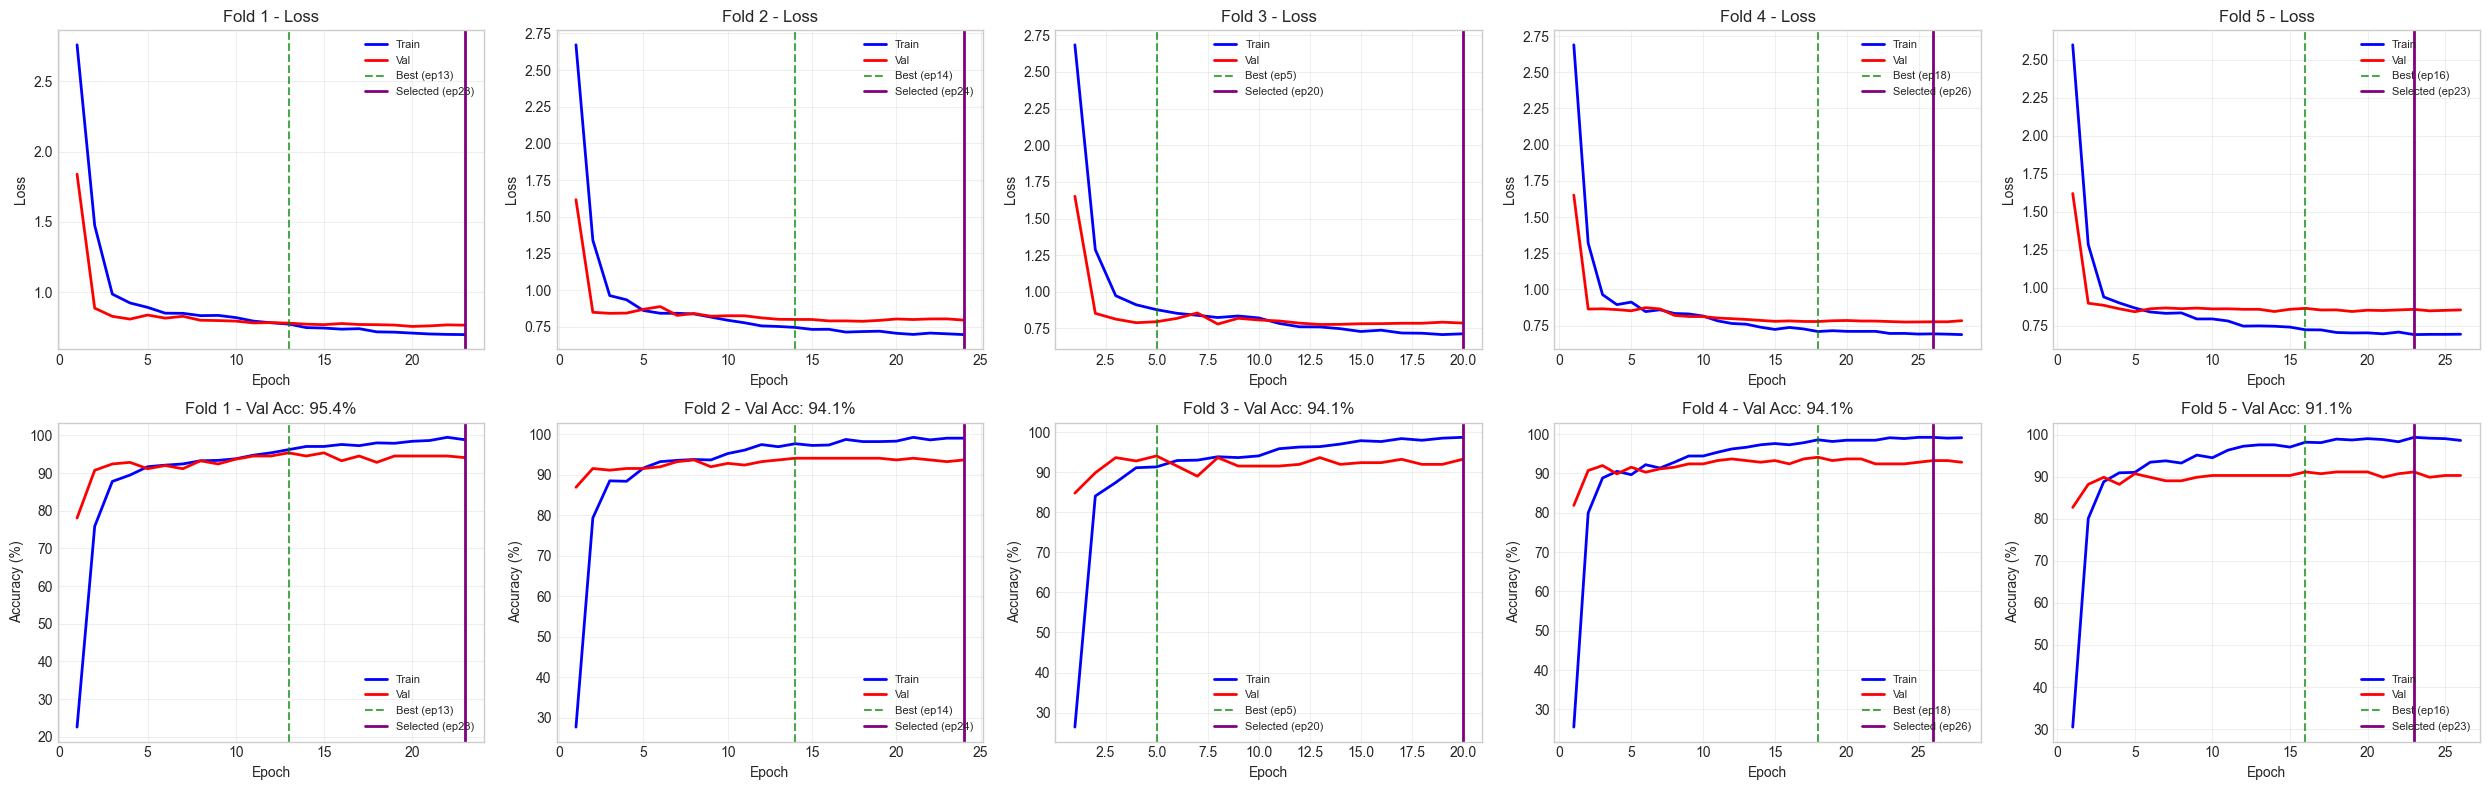


Your Selection Summary:
Fold 1: Epoch 23 → Val Acc: 94.09% (Best was 95.36%, diff: -1.27%)
Fold 2: Epoch 24 → Val Acc: 93.67% (Best was 94.09%, diff: -0.42%)
Fold 3: Epoch 20 → Val Acc: 93.25% (Best was 94.09%, diff: -0.84%)
Fold 4: Epoch 26 → Val Acc: 93.25% (Best was 94.09%, diff: -0.84%)
Fold 5: Epoch 23 → Val Acc: 91.14% (Best was 91.14%, diff: +0.00%)

Expected Mean Val Acc: 93.08% ± 1.02%


In [21]:
# ============================================
# STEP 2: Define Your Manual Epoch Selection
# ============================================
# Based on the training history above, select which epoch to use for each fold

# EDIT THIS: Specify which epoch you want for each fold
# Look at the training history and pick epochs that seem to generalize well
# (not necessarily the best validation accuracy - sometimes earlier epochs generalize better)

my_epoch_selection = {
    1: 23,  # Fold 1: using epoch 4 (edit based on your observation)
    2: 24,  # Fold 2: using epoch 4
    3: 20,  # Fold 3: using epoch 4
    4: 26,  # Fold 4: using epoch 4
    5: 23  # Fold 5: using epoch 4

}

# Visualize your selection on the training curves
plot_fold_histories(fold_results, show_selection=my_epoch_selection)

# Print summary of your selection
print("\nYour Selection Summary:")
print("="*60)
for fold, epoch in my_epoch_selection.items():
    # Find the validation accuracy for this epoch
    result = fold_results[fold - 1]
    epoch_idx = result['history']['epoch'].index(epoch)
    val_acc = result['history']['val_acc'][epoch_idx]
    best_acc = result['best_val_acc']
    diff = val_acc - best_acc
    print(f"Fold {fold}: Epoch {epoch} → Val Acc: {val_acc:.2f}% (Best was {best_acc:.2f}%, diff: {diff:+.2f}%)")

# Calculate expected mean accuracy
selected_accs = []
for fold, epoch in my_epoch_selection.items():
    result = fold_results[fold - 1]
    epoch_idx = result['history']['epoch'].index(epoch)
    selected_accs.append(result['history']['val_acc'][epoch_idx])
print(f"\nExpected Mean Val Acc: {np.mean(selected_accs):.2f}% ± {np.std(selected_accs):.2f}%")

In [22]:
# ============================================
# STEP 3: Create Ensemble with Selected Epochs & Run Predictions
# ============================================

# Create the custom ensemble using your epoch selections
# This uses the epoch_checkpoints saved in fold_results (requires save_all_epochs=True)
custom_models = get_epoch_models_from_results(fold_results, my_epoch_selection, device)

# Run predictions with TTA
print("\nRunning predictions with custom epoch selection...")
custom_predictions, custom_filenames = predict_with_tta_ensemble(
    custom_models, 
    TEST_PATH, 
    config, 
    device
)

print(f"\n✓ Predictions generated for {len(custom_predictions)} images")

Creating Ensemble from Training Results:
  Fold 1: ✓ Epoch 23 (Val Acc: 94.09%)
  Fold 2: ✓ Epoch 24 (Val Acc: 93.67%)
  Fold 3: ✓ Epoch 20 (Val Acc: 93.25%)
  Fold 4: ✓ Epoch 26 (Val Acc: 93.25%)
  Fold 5: ✓ Epoch 23 (Val Acc: 91.14%)

✓ Ensemble created with 5 models

Running predictions with custom epoch selection...
TTA Ensemble Prediction Settings:
  Test images found: 400
  Models in ensemble: 5
  TTA variants: 5
  Total predictions per image: 25
  TTA voting method: mean
  Ensemble voting method: mean


Predicting with TTA Ensemble:   0%|          | 0/400 [00:00<?, ?it/s]


✓ Predictions generated for 400 images


In [23]:
# ============================================
# STEP 4: Create Submission with Custom Epoch Selection
# ============================================

import os
import json
from datetime import datetime

# Create submission dataframe
custom_submission_df = pd.DataFrame({
    'path': custom_filenames,
    'class_idx': custom_predictions
})
custom_submission_df = custom_submission_df.sort_values('path').reset_index(drop=True)

# Generate folder name (indicating custom selection)
model_arch = config.model_name.split('.')[0].replace('tf_', '').replace('_', '')
voting_mode = f'{config.tta_voting[0]}{config.ensemble_voting[0]}'
head_type = getattr(config, 'head_type', 'default')

experiment_parts = [
    f'img{config.img_size}',
    f'{len(my_epoch_selection)}fold',
    'custom-epochs',  # Indicates custom epoch selection
]
# Add head type if not default
if head_type != 'default':
    experiment_parts.append(f'head-{head_type}')
experiment_parts.extend([
    f'tta{len(get_tta_transforms(config))}-{voting_mode}',
    datetime.now().strftime('%Y%m%d_%H%M')
])
experiment_name = '_'.join(experiment_parts)

# Create folder
experiment_dir = os.path.join('submissions', model_arch, experiment_name)
os.makedirs(experiment_dir, exist_ok=True)

# Save submission
submission_path = os.path.join(experiment_dir, 'submission.csv')
custom_submission_df.to_csv(submission_path, index=False)

# Save config with epoch selection details
config_info = {
    'model_name': config.model_name,
    'img_size': config.img_size,
    'head_type': getattr(config, 'head_type', 'default'),
    'head_hidden_dim': getattr(config, 'head_hidden_dim', 512),
    'head_dropout': getattr(config, 'head_dropout', 0.3),
    'tta_variants': len(get_tta_transforms(config)),
    'tta_voting': config.tta_voting,
    'ensemble_voting': config.ensemble_voting,
    'custom_epoch_selection': my_epoch_selection,
    'selected_fold_accuracies': {
        str(fold): fold_results[fold - 1]['history']['val_acc'][
            fold_results[fold - 1]['history']['epoch'].index(epoch)
        ]
        for fold, epoch in my_epoch_selection.items()
    },
    'expected_mean_val_accuracy': np.mean(selected_accs),
    'timestamp': datetime.now().isoformat()
}

config_path = os.path.join(experiment_dir, 'experiment_config.json')
with open(config_path, 'w') as f:
    json.dump(config_info, f, indent=2)

print(f"{'='*60}")
print(f"Custom Epoch Selection Submission Saved!")
print(f"{'='*60}")
print(f"  Location: {experiment_dir}/")
print(f"  Epoch Selection: {my_epoch_selection}")
print(f"  Expected Mean Val Acc: {np.mean(selected_accs):.2f}%")
print(f"\n✓ submission.csv")
print(f"✓ experiment_config.json")

Custom Epoch Selection Submission Saved!
  Location: submissions/convnexttiny/img384_5fold_custom-epochs_head-mlp_tta5-mm_20260201_1421/
  Epoch Selection: {1: 23, 2: 24, 3: 20, 4: 26, 5: 23}
  Expected Mean Val Acc: 93.08%

✓ submission.csv
✓ experiment_config.json


# Summary

## Experiment Configuration
- **Model**: EfficientNetV2-S (pretrained on ImageNet-21K, fine-tuned on ImageNet-1K)
- **Cross-Validation**: 5-Fold Stratified K-Fold
- **Image Size**: 384×384
- **Batch Size**: 16

## Transfer Learning Strategy
- **Two-Stage Training**:
  1. **Stage 1 (Frozen Backbone)**: Train classifier head only for 5 epochs
     - Learning Rate: 1e-3 (higher for new head)
     - Only classifier parameters are trainable
  2. **Stage 2 (Fine-tuning)**: Progressive unfreezing for 10 epochs
     - **Progressive Unfreezing** (default): Only unfreeze last 2 blocks + classifier
       - Preserves early layers (general features like edges, textures)
       - Fine-tunes later layers (task-specific features)
       - More stable and computationally efficient
     - **Alternative**: Can unfreeze all layers if `unfreeze_all_layers=True`
     - Backbone LR: 1e-5 (lower to preserve pretrained features)
     - Head LR: 1e-4 (reduced from Stage 1)
- **Total Epochs**: 15 per fold (with early stopping, patience=5)

## Data Augmentation (Training)
- Random Resized Crop (scale 0.8-1.0)
- Random Horizontal Flip (p=0.5)
- Random Rotation (±15°)
- Color Jitter (brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1)
- Random Erasing/Cutout (p=0.25)

## Test Time Augmentation (TTA)
- Original image
- Horizontal flip
- +10° rotation
- -10° rotation
- Center crop from 1.1× resize

## Ensemble Strategy
- Soft voting across all K-fold models
- Probability averaging across TTA variants
- Final prediction: argmax of averaged probabilities

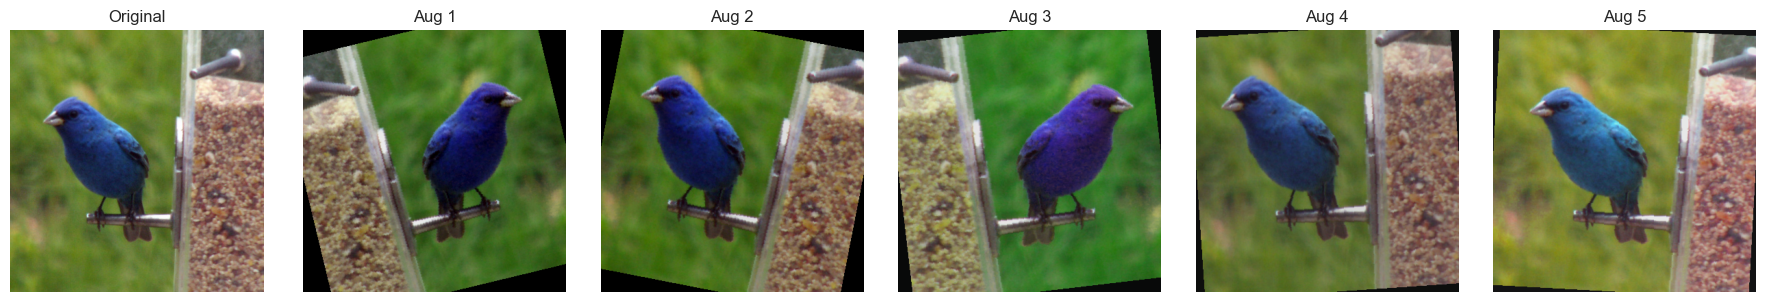

In [88]:
# ============================================
# Visualize Sample Augmentations (Optional)
# ============================================

def visualize_augmentations(image_path, config, n_samples=5):
    """Visualize different augmentations applied to a single image"""
    train_transforms = get_train_transforms(config)
    
    image = Image.open(image_path).convert('RGB')
    
    fig, axes = plt.subplots(1, n_samples + 1, figsize=(3*(n_samples+1), 3))
    
    # Original
    axes[0].imshow(image)
    axes[0].set_title('Original')
    axes[0].axis('off')
    
    # Augmented versions
    for i in range(n_samples):
        aug_tensor = train_transforms(image)
        # Denormalize for visualization
        aug_img = aug_tensor.permute(1, 2, 0).numpy()
        aug_img = aug_img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
        aug_img = np.clip(aug_img, 0, 1)
        
        axes[i+1].imshow(aug_img)
        axes[i+1].set_title(f'Aug {i+1}')
        axes[i+1].axis('off')
    
    plt.tight_layout()
    plt.show()

# Example: visualize augmentations on a sample image
sample_image = list(TRAIN_PATH.glob('*/*.jpg'))[0]
visualize_augmentations(sample_image, config)

In [89]:
# ============================================
# Confusion Matrix Visualization (Optional)
# ============================================

def plot_confusion_matrix(y_true, y_pred, class_names):
    """Plot confusion matrix"""
    cm = confusion_matrix(y_true, y_pred)
    
    fig, ax = plt.subplots(figsize=(14, 12))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()

# This can be called after validation if you have true labels
# class_names = list(class_mapping.keys())
# plot_confusion_matrix(val_labels, val_preds, class_names)